# ELM: CE / Data 모델 분리
학습 순서는 CE 완료 후 Data로 고정합니다. 실행 대상은 기존 1-slot 데이터입니다.


In [1]:
import torch
import torch.nn as nn
import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path
from contextlib import contextmanager
from tqdm import tqdm as _tqdm
from functools import partial
# 현재 작업만 같은 줄에 표시하고, 완료된 작업 bar는 지웁니다.
tqdm = partial(_tqdm, leave=False, position=0, dynamic_ncols=True, mininterval=0.5)
from IPython.display import HTML, display
from html import escape
import copy
import csv
import hashlib
import json
import math
import os
import random
import tempfile
import time

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

BATCH_SIZE = 1024

SEED = 42

EPOCHS = 1000
LR = .001
WEIGHT_DECAY = 1e-6
EARLY_STOPPING = True
PATIENCE = 100


In [2]:
# 공통 입출력: 기존 1-slot 데이터. Port는 1로 고정합니다.
# [2] / [11] / [2,11]. n_slots=1일 때 history_symbols는 입력에 포함되지 않습니다.
# 실제 크기는 아래 설정으로 계산하며, R/I ×2를 포함하여 실행 시 출력합니다.
LAYOUT_LIST = ['All', 'ARSeparate', 'ARShared', 'ARAnchorSeparate', 'ARAnchorShared', 'Joint']
COMMON_CONFIG = {
    'n_slots': 1,
    'history_symbols': [2, 11],
    'current_symbols': [2],
    'rs_subcarriers': list(range(0,119,2)),
    'data_subcarriers': list(range(119)),
    'data_symbols': list(range(3,11)),
}


In [3]:
# Part 1. CE: 전체 LS 입력 -> 지정한 현재 슬롯 RS 채널 정답.
# CE 학습 완료 후 고정. Train 출력만 CE_Train.h5로 저장하고 Data Train에서 읽습니다.
# Data input='LS'인 경우 이 Part는 학습·추론·출력 저장을 모두 생략합니다.
CE_CONFIG = {
    'output_symbols': 'current',  # 현재 관측 심볼을 자동 반영. [2], [11], [2,11]로 직접 지정 가능.
    'model': {'hidden': [512]},
    'model_by_layout': {},
}


In [4]:
# Part 2. Data: CE 출력 또는 LS를 선택. 크기는 CE와 독립적으로 설정합니다.
# context='Current': 현재 슬롯만 / 'History': 과거 LS + 현재 CE(또는 현재 LS).
# 현재 실행은 1-slot만 사용하므로 두 context의 관측 슬롯은 같습니다.
# Shared Train은 고정 Real 이전 prefix, Val/Test는 실제 Student rollout입니다.
DATA_CONFIG = {
    'input': 'LS',  # 'CE' / 'LS'
    'context': 'Current',
    'input_by_layout': {'Joint':'LS'},
    'context_by_layout': {},
    'model': {'hidden': [256]},
    'model_by_layout': {'All': {'hidden': [1024]}, 'Half': {'hidden': [512]}},
}

Distillation = False  # True: Data Teacher의 Train 중간/최종 출력도 저장


In [5]:
DATA_ROOT = Path('E:/DMRS Channel')
DATA_BRANCH = 'SISO'  # 현재 학습 모델은 1 Tx 포트·1 Rx 입력. 다중 안테나 데이터는 별도 상위 폴더에 저장.
MIXED = True  # True: Mix 데이터 / False: Fix 데이터
DRIVE = DATA_ROOT / DATA_BRANCH / ('Mix' if MIXED else 'Fix')
PROJECT_ROOT = next((p for p in (Path.cwd(),Path.cwd()/'DMRS Channel Estimation') if (p/'Data_Generation_DMRS.ipynb').is_file()),Path(r'C:/Users/ychan/Desktop/VScode/DMRS Channel Estimation'))
RESULT_ROOT = PROJECT_ROOT/'CE_Result'
MIX_CHANNEL_TYPE = 'CDL-C'  # TDL-A~E / CDL-A~E. 여러 채널 종류를 함께 Mix했으면 'Mixed'.
CHANNEL_TYPE = 'CDL-C'
TRAIN_DELAY_LIST = [25, 75, 150, 200, 300]
TRAIN_DOPPLER_LIST = [50, 200, 500]
TRAIN_SNR_LIST = [-10, 0, 10, 20]
TEST_CHANNEL_TYPE_LIST = ['CDL-C']  # 예: ['TDL-A','TDL-B','TDL-C','TDL-D','TDL-E','CDL-A','CDL-B','CDL-C','CDL-D','CDL-E']
TEST_DELAY_LIST = [25, 75, 150, 200, 300]
TEST_DOPPLER_LIST = [50, 200, 500]
TEST_SNR_LIST = [-10, -5, 0, 5, 10, 15, 20]
SOURCE_FILES = []
MAX_SAMPLES_PER_CONDITION = None
ELM_RIDGE_LIST = [1e-06, 0.0001, 0.01, 0.1, 1.0]
DATA_CACHE_DEVICE = 'auto'
if not MIXED:
    TEST_CHANNEL_TYPE_LIST=[CHANNEL_TYPE]
    TEST_DELAY_LIST=TRAIN_DELAY_LIST
    TEST_DOPPLER_LIST=TRAIN_DOPPLER_LIST
    TEST_SNR_LIST=TRAIN_SNR_LIST


In [6]:
MODEL_NAME = 'ELM'
MODEL_FAMILY = MODEL_NAME
FEATURE_LAYOUT = 'flat[real.flatten(subcarrier,symbol),imag.flatten(subcarrier,symbol)]'
class RegressionNet(nn.Module):

    def __init__(self, n_input, n_output, hidden_layer):
        super().__init__()
        self.n_input = n_input
        self.n_output = n_output
        sizes = ([] if hidden_layer == 0 else [hidden_layer]) if isinstance(hidden_layer, int) else list(hidden_layer)
        if any((size <= 0 for size in sizes)):
            raise ValueError('Hidden Layer 크기는 양수로 입력하세요.')
        layers = []
        previous = n_input
        for size in sizes:
            layers.append(nn.Linear(previous, size))
            layers.append(nn.GELU())
            previous = size
        self.fixed_features = nn.Sequential(*layers) if layers else nn.Identity()
        self.readout = nn.Linear(previous, n_output)
        for parameter in self.fixed_features.parameters():
            parameter.requires_grad_(False)
        nn.init.zeros_(self.readout.weight)
        nn.init.zeros_(self.readout.bias)

    def get_features(self, x):
        return self.fixed_features(x)

    def forward(self, x):
        return self.readout(self.get_features(x))


# Model Naming / 입출력 크기 계산
def model_spec(layout):
    aliases={'All2':'All','AR2Separate':'ARAnchorSeparate','AR2Shared':'ARAnchorShared',
             'ARCumulativeSeparate':'ARCSeparate','ARCumulativeShared':'ARCShared',
             'HistoryCE':'All','HistoryCE2':'All','HistoryCEFull':'All',
             'HistoryCE2Full':'All','HistoryJoint':'Joint','HistoryJoint2':'Joint'}
    import re
    old=re.sub(r'_nslot\d+$','',layout)
    name=aliases.get(old,old)
    allowed={'All','Half','One','ARSeparate','ARShared','ARAnchorSeparate','ARAnchorShared',
             'ARCSeparate','ARCShared','Joint'}
    if name not in allowed:raise ValueError(f'지원 Layout: {sorted(allowed)}; 입력={layout}')
    c=COMMON_CONFIG
    slots=c['n_slots']
    if not isinstance(slots,int) or isinstance(slots,bool) or slots<1:raise ValueError('n_slots는 양의 정수입니다.')
    for key,allowed_values in [('history_symbols',{2,11}),('current_symbols',{2,11})]:
        values=c[key]
        if not values or len(set(values))!=len(values) or not set(values)<=allowed_values:
            raise ValueError(f'{key}: [2], [11], [2,11] 중 선택하세요.')
    observed=[(slot,s) for slot in range(slots-1) for s in c['history_symbols']]
    observed += [(slots-1,s) for s in c['current_symbols']]
    source=DATA_CONFIG.get('input_by_layout',{}).get(name,DATA_CONFIG['input'])
    rs_symbols=(c['current_symbols'] if source=='LS' and name!='Joint' else
                c['current_symbols'] if CE_CONFIG['output_symbols']=='current' else CE_CONFIG['output_symbols'])
    if not rs_symbols or len(set(rs_symbols))!=len(rs_symbols) or not set(rs_symbols)<={2,11}:
        raise ValueError('CE output_symbols: [2], [11], [2,11].')
    for key in ['rs_subcarriers','data_subcarriers','data_symbols']:
        values=c[key]
        if not values or list(values)!=sorted(set(values)):raise ValueError(f'{key}는 오름차순 중복 없는 List입니다.')
    if not set(c['rs_subcarriers'])<=set(range(0,119,2)):raise ValueError('RS 위치는 원본 Comb2 범위 안이어야 합니다.')
    if not set(c['data_subcarriers'])<=set(range(119)):raise ValueError('Data subcarrier 범위는 0~118입니다.')
    if not set(c['data_symbols'])<=set(range(3,11)):raise ValueError('Data symbol 범위는 3~10입니다.')
    if source not in ('LS','CE'):raise ValueError('Data input은 LS 또는 CE입니다.')
    if name=='Joint' and source!='LS':raise ValueError('Joint는 LS 입력으로 CE+Data를 함께 출력합니다. input_by_layout[Joint]=LS로 설정하세요.')
    context=DATA_CONFIG.get('context_by_layout',{}).get(name,DATA_CONFIG['context'])
    if context not in ('Current','History'):raise ValueError('Data context는 Current 또는 History입니다.')
    nr,nd=len(c['rs_subcarriers']),len(c['data_subcarriers'])
    data_input_count=(len(observed)-len(c['current_symbols'])+(len(rs_symbols) if source=='CE' else len(c['current_symbols']))
                      if context=='History' else len(rs_symbols) if source=='CE' else len(c['current_symbols']))
    if source=='CE' and not set(c['current_symbols'])<=set(rs_symbols) and context=='History':
        raise ValueError('History CE 입력은 현재 관측 부분을 CE output_symbols로 교체합니다. 현재 심볼을 CE 출력에 포함하세요.')
    spec=dict(name=name,n_slots=slots,history=slots>1,observed_positions=[list(p) for p in observed],
        input_symbols=len(observed),target_slot=slots-1,rs_symbols=list(rs_symbols),
        rs_shape=[nr,len(rs_symbols)],data_shape=[nd,len(c['data_symbols'])],
        input_shape=[nr,len(observed),2],ce_output_shape=[nr,len(rs_symbols),2],
        data_input_shape=[nr,data_input_count,2],data_output_shape=[nd,len(c['data_symbols']),2],
        data_symbols=list(c['data_symbols']),rs_subcarriers=list(c['rs_subcarriers']),
        data_subcarriers=list(c['data_subcarriers']),current_symbols=list(c['current_symbols']),
        source=source,context=context,joint=name=='Joint',data_input_count=data_input_count)
    return spec


def config_for(part,layout):
    result=copy.deepcopy(part['model'])
    result.update(copy.deepcopy(part.get('model_by_layout',{}).get(layout,{})))
    return result


def grid_name(spec):
    return f"RS{spec['input_shape'][0]}x{spec['input_shape'][1]}_Data{spec['data_shape'][0]}x{spec['data_shape'][1]}_BWP120"


def model_identity(spec):
    config=dict(format='dmrs-model-parts-1.0',family=MODEL_NAME,common=COMMON_CONFIG,spec=spec,
                ce=config_for(CE_CONFIG,spec['name']) if spec['source']=='CE' else None,
                data=config_for(DATA_CONFIG,spec['name']))
    if MODEL_NAME=='ELM_Distill':config['distillation']=DISTILL_CONFIG
    digest=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:12]
    def tag(c):
        if c is None:return 'Bypass'
        if 'embed_dim' in c:return f"E{c['embed_dim']}D{c['depth']}M{c['mlp_dim']}H{c['num_heads']}"
        return 'x'.join(map(str,c.get('hidden',[]))) or 'Linear'
    case=f"CE{tag(config['ce'])}_Data{tag(config['data'])}_Input{spec['source']}_{spec['context']}_nslot{spec['n_slots']}_Cfg{digest}"
    return config,case


def layout_spec(layout):
    return model_spec(layout)  # 데이터 로더는 실제 슬롯 축을 확인합니다.


# CE / Data Model 구현
class ChannelMap(nn.Module):
    def __init__(self,input_shape,output_shape,configuration,student_middle=None,family=None):
        super().__init__()
        self.input_shape,self.output_shape=tuple(input_shape),tuple(output_shape)
        self.family=family or MODEL_NAME
        if self.family=='Transformer':
            self.encoder=SymbolTransformerEncoder(configuration,2*input_shape[1],input_shape[0])
            self.readout=nn.Linear(2*input_shape[1]*configuration['embed_dim'],2*int(np.prod(output_shape)))
        elif self.family=='ELM_Distill':
            if student_middle is None:raise ValueError('같은 Layout의 Teacher Train Feature에서 중간 크기를 먼저 선택하세요.')
            self.stage1=RegressionNet(2*int(np.prod(input_shape)),student_middle,configuration['stage1_hidden'])
            self.stage2=RegressionNet(student_middle,2*int(np.prod(output_shape)),configuration['stage2_hidden'])
        else:self.net=RegressionNet(2*int(np.prod(input_shape)),2*int(np.prod(output_shape)),configuration['hidden'])

    def forward(self,x):
        if self.family=='Transformer':value=self.readout(self.encoder(x).flatten(1))
        elif self.family=='ELM_Distill':value=self.stage2(self.stage1(x.flatten(1)))
        else:value=self.net(x.flatten(1))
        if FEATURE_LAYOUT.startswith('matrix'):return value.reshape(len(x),self.output_shape[0],2*self.output_shape[1])
        return value


def stage_pack(anchor,previous,index,spec,shared=False,cumulative=False,keep_anchor=False):
    nr,na=spec['data_input_shape'][:2];nd=spec['data_shape'][0];steps=spec['data_shape'][1]
    a=channels(anchor,(nr,na))
    if index==0 and not cumulative:return anchor
    count=(steps-1 if shared else index) if cumulative else 1
    history=a.new_zeros((len(a),nd,count))
    if index:
        predicted=channels(previous,(nd,index if cumulative else 1))
        history[:,:,:predicted.shape[-1]]=predicted
    if not cumulative and not keep_anchor:return previous
    if FEATURE_LAYOUT.startswith('matrix'):
        state=a.new_zeros((len(a),max(nr,nd),na+count))
        state[:,:nr,:na]=a;state[:,:nd,na:]=history
        return features(state)
    return features(torch.cat((a.flatten(1),history.flatten(1)),dim=1))


class DataBranch(nn.Module):
    def __init__(self,spec,config,middle_sizes=None):
        super().__init__();self.spec=spec;self.layout=spec['name'];self.capture=False;self.steps={}
        name=self.layout;nr,na=spec['data_input_shape'][:2];nd,nt=spec['data_shape']
        self.cumulative=name.startswith('ARC');self.autoregressive=name.startswith('AR')
        self.shared=name.endswith('Shared');self.keep_anchor=name.startswith('ARAnchor')
        if self.cumulative:
            sizes=[(nt-1,nt)] if self.shared else [(i,i+1) for i in range(nt)]
            dimensions=[((max(nr,nd),na+i) if FEATURE_LAYOUT.startswith('matrix') else (nr*na+nd*i,1),(nd,o)) for i,o in sizes]
        elif self.autoregressive:
            dimensions=[((nr,na),(nd,1))]
            following=((max(nr,nd),na+1) if FEATURE_LAYOUT.startswith('matrix') else (nr*na+nd,1)) if self.keep_anchor else (nd,1)
            dimensions += [(following,(nd,1))]*((1 if self.shared else nt-1) if nt>1 else 0)
        elif name=='Half':
            cut=(nt+1)//2
            if nt<2:raise ValueError('Half에는 Data 심볼이 2개 이상 필요합니다.')
            half_input=(nr,1) if spec['context']=='Current' and na==2 else (nr,na)
            dimensions=[(half_input,(nd,cut)),(half_input,(nd,nt-cut))]
        elif name=='One':dimensions=[((nr,na),(nd,1))]*nt
        else:dimensions=[((nr,na),(nd,nt))]
        self.dimensions=dimensions
        self.heads=nn.ModuleList([ChannelMap(a,b,config,None if middle_sizes is None else middle_sizes[i])
                                  for i,(a,b) in enumerate(dimensions)])

    def index(self,step):return 0 if self.cumulative and self.shared else (0 if step==0 else 1) if self.shared else step

    def prefix(self,value,count,total=None):
        total=self.spec['data_shape'][1] if total is None else total
        return features(channels(value,(self.spec['data_shape'][0],total))[:,:,:count])

    def head_input(self,anchor,index):
        nr,na=self.spec['data_input_shape'][:2]
        if self.layout=='Half' and self.spec['context']=='Current' and na==2:
            return features(channels(anchor,(nr,na))[:,:,index:index+1])
        return anchor

    def step(self,anchor,previous,index):
        state=stage_pack(anchor,previous,index,self.spec,self.shared,self.cumulative,self.keep_anchor)
        output=self.heads[self.index(index)](state)
        if self.cumulative and self.shared:output=self.prefix(output,index+1)
        return state,output

    def forward(self,anchor):
        nt=self.spec['data_shape'][1];previous=None;values=[];self.steps.clear()
        if self.autoregressive:
            for step in range(nt):
                self.active_step=step
                state,previous=self.step(anchor,previous,step)
                if self.capture:self.steps[step]=dict(input=state.detach(),output=previous.detach())
                if not self.cumulative:values.append(channels(previous,(self.spec['data_shape'][0],1)))
            return previous if self.cumulative else features(torch.cat(values,2))
        for i,head in enumerate(self.heads):
            self.active_step=i
            inputs=self.head_input(anchor,i)
            output=head(inputs);values.append(channels(output,head.output_shape))
            if self.capture:self.steps[i]=dict(input=inputs.detach(),output=output.detach())
        return features(torch.cat(values,2))


class ChannelModel(nn.Module):
    def __init__(self,spec,ce_config,data_config,middle_sizes=None):
        super().__init__();self.spec=spec;self.layout=spec['name'];seed_everything(SEED)
        self.ce=None
        if spec['source']=='CE':self.ce=ChannelMap(spec['input_shape'][:2],spec['rs_shape'],ce_config,
                                                family='Transformer' if MODEL_NAME=='ELM_Distill' else None)
        seed_everything(SEED+1000)
        if spec['joint']:
            self.joint=ChannelMap(spec['input_shape'][:2],(1,int(np.prod(spec['rs_shape']))+int(np.prod(spec['data_shape']))),data_config,
                                   None if middle_sizes is None else middle_sizes[0])
        else:self.data=DataBranch(spec,data_config,middle_sizes)

    def data_input(self,x,ce):
        s=self.spec;raw=channels(x,tuple(s['input_shape'][:2]));count=len(s['current_symbols'])
        current=channels(ce,tuple(s['rs_shape'])) if s['source']=='CE' else raw[:,:,-count:]
        return features(torch.cat((raw[:,:,:-count],current),2) if s['context']=='History' else current)

    def forward(self,x):
        s=self.spec
        if s['joint']:
            flat=self.joint(x).flatten(1);width=2*int(np.prod(s['rs_shape']))
            a,b=flat[:,:width],flat[:,width:]
            if FEATURE_LAYOUT.startswith('matrix'):
                a=a.reshape(len(x),s['rs_shape'][0],2*s['rs_shape'][1])
                b=b.reshape(len(x),s['data_shape'][0],2*s['data_shape'][1])
            return a,b
        if self.ce is not None:a=self.ce(x)
        else:
            raw=channels(x,tuple(s['input_shape'][:2]));latest={symbol:i for i,symbol in enumerate(s['current_symbols'])}
            if not set(s['rs_symbols'])<=set(latest):
                raise ValueError('LS bypass의 CE 표시 영역은 현재 관측한 심볼만 선택하세요.')
            a=features(raw[:,:,-len(latest):][:,:,[latest[symbol] for symbol in s['rs_symbols']]])
        return a,self.data(self.data_input(x,a))



In [7]:
RANDOM_ALLOCATION = 'DMRS SC60xSym2 P1 Comb2 RB0-9 l2,11'
def features(z):
    if not torch.is_complex(z):
        raise TypeError('Channel must be complex.')
    return torch.cat((z.real.flatten(1), z.imag.flatten(1)), dim=1).float()


def channels(x, shape):
    count = int(np.prod(shape))
    if x.shape[-1] != 2 * count:
        raise ValueError('Feature count differs from channel shape.')
    return torch.complex(x[:, :count].reshape(-1, *shape), x[:, count:].reshape(-1, *shape))


def filesystem_path(path):
    value = str(path)
    if value.startswith('\\\\?\\UNC\\'):
        value = '\\\\' + value[8:]
    elif value.startswith('\\\\?\\'):
        value = value[4:]
    value = os.path.abspath(os.path.normpath(value))
    if os.name == 'nt':
        value = '\\\\?\\UNC\\' + value[2:] if value.startswith('\\\\') else '\\\\?\\' + value
    return Path(value)


def write_json(path, value):
    path = filesystem_path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def compute_train_stats(training_ls):
    # Test / Validation에서는 다시 계산하지 않습니다.
    mean = np.mean(training_ls, dtype=np.complex128)
    scale = np.sqrt(np.mean(np.abs(training_ls - mean) ** 2, dtype=np.float64) / 2)
    return dict(mean_real=float(mean.real), mean_imag=float(mean.imag), scale=max(float(scale), 1e-8))


def normalize_data(channel, stats):
    mean = complex(stats['mean_real'], stats['mean_imag'])
    return features((torch.as_tensor(channel) - mean) / stats['scale'])


def denormalize_data(value, shape, stats):
    mean = complex(stats['mean_real'], stats['mean_imag'])
    return channels(value, shape) * stats['scale'] + mean


def select_source_rows(bounds, limit=None):
    names = ('train', 'val', 'test')
    counts = np.array([bounds[name][1]-bounds[name][0] for name in names], dtype=np.int64)
    if np.any(counts < 0) or counts.sum() == 0:
        raise ValueError('저장 데이터의 split 범위가 잘못되었습니다.')
    take = counts.copy()
    if limit is not None and limit < counts.sum():
        if limit < np.count_nonzero(counts):
            raise ValueError('존재하는 각 split에 최소 한 개의 샘플이 필요합니다.')
        exact = limit*counts/counts.sum()
        minimum = (counts > 0).astype(int)
        take = np.minimum(counts, np.maximum(minimum, np.floor(exact).astype(int)))
        while take.sum() < limit:
            take[np.argmax(np.where(take < counts, exact-take, -np.inf))] += 1
        while take.sum() > limit:
            take[np.argmax(np.where(take > minimum, take-exact, -np.inf))] -= 1
    rows, parts, offset = [], {}, 0
    for name, count in zip(names, take):
        rows.extend(range(bounds[name][0], bounds[name][0]+int(count)))
        parts[name] = np.arange(offset, offset+int(count), dtype=np.int64)
        offset += int(count)
    return np.asarray(rows, dtype=np.int64), parts


def find_sources(channel_types, delays, dopplers, snrs, n_slots=1, strict=False):
    """실제 slot 축으로 구분합니다. 1슬롯에 5슬롯의 slot 0을 대신 사용하지 않습니다."""
    root = filesystem_path(DRIVE)
    paths = [filesystem_path(p) for p in SOURCE_FILES] if SOURCE_FILES else sorted(root.rglob('*.h5'))
    expected = {(ch, float(d), float(f), float(s)) for ch in channel_types
                for d in delays for f in dopplers for s in snrs}
    found = {}
    for path in paths:
        if path.name.startswith('.') or '.partial' in path.name:
            continue
        try:
            with h5py.File(path, 'r') as file:
                if ('LS_Channel' not in file or file.attrs.get('rs_kind') != 'dmrs'
                        or str(file.attrs.get('storage_mode', '')).startswith('random_mix')
                        or file.attrs.get('status') != 'complete'
                        or file.attrs.get('estimator_policy') != 'per_re_siso_cdm_multiport_v1'):
                    continue
                slots = int(file.attrs.get('n_slots', file['LS_Channel'].shape[1]))
                if file['LS_Channel'].shape[2:4] != (1,1):
                    raise ValueError('현재 학습 모델은 SISO 입력입니다. MISO/MIMO에서 포트 하나만 임의로 잘라 읽지 않습니다.')
                if slots != n_slots or file['LS_Channel'].shape[1] != slots:
                    continue
                config = json.loads(file.attrs['config_json'])
                condition = json.loads(file.attrs['condition_json'])
                key = (condition['backend'].upper()+'-'+condition['profile'],
                       float(condition['delay_spread_ns']), float(condition['doppler_hz']), float(condition['snr_db']))
                if key not in expected or config['carrier']['scs_khz'] != 15:
                    continue
                files = {k: str(filesystem_path(path.parent/v))
                         for k, v in json.loads(file.attrs['file_set_json']).items()}
                ranges = json.loads(file.attrs['split_ranges_json'])
                if ranges['test'][1] <= ranges['test'][0]:
                    continue
                source = dict(anchor=str(path), generation_id=str(file.attrs['generation_id']),
                    condition=condition, config=config, files=files, split_ranges=ranges,
                    n_slots=slots, implementation_sha256=str(file.attrs['implementation_sha256']))
            paired=True
            for quantity,dataset in [('real','Real_Channel'),('mmse','MMSE_Channel')]:
                with h5py.File(files['dmrs/'+quantity], 'r') as other:
                    paired &= (other.attrs.get('status') == 'complete'
                        and other.attrs.get('generation_id') == source['generation_id']
                        and other.attrs.get('estimator_policy') == 'per_re_siso_cdm_multiport_v1'
                        and other[dataset].shape[:4] == (ranges['test'][1],n_slots,1,1))
            if not paired:continue
            # Prefer an uninterpolated original; both carry the same actual pilot coordinates.
            if key not in found or ('Interp2D' in found[key]['anchor'] and 'Interp2D' not in str(path)):
                found[key] = source
        except OSError:
            continue  # 아직 생성 중이거나 다른 프로세스가 쓰는 Test 파일은 다음 실행에서 평가합니다.
    missing = expected-set(found)
    if missing:
        print(f'nslot{n_slots}: 준비된 Test {len(found)}/{len(expected)}개 환경; 미완료 환경은 건너뜁니다.')
        if strict:
            raise FileNotFoundError(f'nslot{n_slots}: 학습할 개별 환경 데이터가 없습니다: {sorted(missing)}')
    return [found[k] for k in sorted(found)]


def cpu_state(model):
    return {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}


def activate_layout_sources(layout):
    """Layout 하나마다 슬롯 수에 맞는 Mix만 확인하고 원본 Test는 준비된 것만 선택합니다."""
    global mix_paths, mix_metadata, mix_id, mix_cache, TRAIN_SOURCES, TEST_SOURCES
    spec = layout_spec(layout)
    slots = spec['n_slots']
    if MIXED:
        allocations = (['DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11', RANDOM_ALLOCATION] if slots == 1
                       else [f'DMRS SC60xSym2 P1 nslot{slots} Comb2 RB0-9 l2,11'])
        chosen = None
        for prefix in ('', 'Interp2D '):
            for plain in allocations:
                paths = {q: filesystem_path(Path(DRIVE)/MIX_CHANNEL_TYPE/f'Random {prefix}{label} Channel'/
                    (prefix+plain)/f'Random {prefix}{label} Channel 2D ({plain}).h5')
                    for q, label in [('ls', 'LS'), ('mmse', 'MMSE'), ('real', 'Real')]}
                if all(path.is_file() for path in paths.values()):
                    chosen = paths
                    break
            if chosen:
                break
        if chosen is None:
            raise FileNotFoundError(f'{layout}: {DRIVE} 아래 nslot{slots} Mix LS/MMSE/Real 파일이 없습니다. '
                                    'Data Generation의 해당 슬롯 Mix 생성을 완료하세요.')
        metadata, identity, sources, order = None, None, None, None
        for q, path in chosen.items():
            if q == 'mmse' and not path.is_file():
                continue
            key = {'ls': 'LS_Channel', 'mmse': 'MMSE_Channel', 'real': 'Real_Channel'}[q]
            with h5py.File(path, 'r') as file:
                if (file.attrs.get('status') != 'complete' or file.attrs.get('format') not in
                        ('dmrs-random-mix-1.0', 'dmrs-multi-slot-random-mix-1.0')):
                    raise ValueError(f'{layout}: Mix 저장이 완료되지 않았습니다: {path}')
                current = json.loads(file['Metadata_JSON'].asstr()[()])
                current_id = str(file.attrs['generation_id'])
                current_sources = json.loads(file['Sources_JSON'].asstr()[()])
                current_order = tuple(file[k][...] for k in ('Source_Index', 'Source_Row', 'Split_Index'))
                actual_slots = int(file.attrs.get('n_slots', file[key].shape[1]))
                if actual_slots != slots or file[key].shape[1] != slots or int(current.get('n_slots', 1)) != slots:
                    raise ValueError(f'{layout}: 요청한 nslot{slots}와 Mix 파일의 실제 슬롯 수가 다릅니다.')
                if (file[key].shape[2:4] != (1,1) or file.attrs.get('cdm_enabled',True)
                        or file.attrs.get('estimator_policy') != 'per_re_siso_cdm_multiport_v1'):
                    raise ValueError('SISO RS별 LS 데이터가 아닙니다. Data Generation copy의 새 SISO Mix를 사용하세요.')
                if json.loads(file.attrs['config_json'])['carrier']['scs_khz'] != 15:
                    raise ValueError('Mix SCS는 15 kHz여야 합니다.')
                counts = current['counts']
                if len(counts) != 3 or min(counts[:2]) <= 0 or counts[2] < 0:
                    raise ValueError('Mix Train/Val은 필수이며 Mix Test는 0개여도 됩니다.')
                if file[key].shape[0] != sum(counts) or int(file.attrs['num_written']) != sum(counts):
                    raise ValueError('Mix의 실제 행 수가 저장 설정과 다릅니다.')
                bounds = np.cumsum([0]+counts)
                for part in range(3):
                    if not np.all(current_order[2][bounds[part]:bounds[part+1]] == part):
                        raise ValueError('Mix Train/Val/Test 분할 순서가 다릅니다.')
                if metadata is None:
                    metadata, identity, sources, order = current, current_id, current_sources, current_order
                elif current != metadata or current_id != identity or current_sources != sources or any(
                        not np.array_equal(a, b) for a, b in zip(current_order, order)):
                    raise ValueError('Mix LS/MMSE/Real의 환경 또는 샘플 순서가 다릅니다.')
        canonical = json.dumps(metadata, sort_keys=True, ensure_ascii=False, separators=(',', ':'))
        if hashlib.sha256(canonical.encode()).hexdigest() != identity:
            raise ValueError('Mix 식별자가 메타데이터와 다릅니다.')
        mix_paths, mix_metadata, mix_id = chosen, metadata, identity
        mix_cache = dict(paths={q: str(p) for q, p in chosen.items()}, mix_id=identity,
                         metadata=metadata, sources=sources)
        TRAIN_SOURCES = [None]
        TEST_SOURCES = random_test_sources(slots)
        if TEST_SOURCES is None:
            print('Random Test가 없어 기존 환경별 Test 파일을 사용합니다. 새 방식은 Data Generation의 Random Test 셀을 실행하세요.')
            TEST_SOURCES = find_sources(TEST_CHANNEL_TYPE_LIST, TEST_DELAY_LIST, TEST_DOPPLER_LIST, TEST_SNR_LIST, slots)
        print(layout, '| nslot:', slots, '| Mix Train/Val/Test:', metadata['counts'], '|', chosen['ls'])
    else:
        TRAIN_SOURCES = find_sources([CHANNEL_TYPE], TRAIN_DELAY_LIST, TRAIN_DOPPLER_LIST, TRAIN_SNR_LIST, slots)
        TRAIN_SOURCES = [s for s in TRAIN_SOURCES if all(s['split_ranges'][p][1] > s['split_ranges'][p][0]
                                                       for p in ('train', 'val'))]
        if not TRAIN_SOURCES:
            raise FileNotFoundError('FIX 학습에는 Train/Val이 있는 개별 환경 데이터가 필요합니다. Test 전용 파일은 MIX 평가용입니다.')
        TEST_SOURCES = TRAIN_SOURCES


def read_parts(files,rows,spec,generation_id=None,need_truth=True):
    data_pair_rows(files,rows,generation_id)
    arrays={}
    keys=[('ls','LS_Channel')]+([('real','Real_Channel')] if need_truth else [])
    for kind,key in keys:
        with h5py.File(files['dmrs/'+kind],'r') as file:
            if generation_id is not None and str(file.attrs['generation_id'])!=str(generation_id):
                raise ValueError('LS/Real의 generation ID가 다릅니다.')
            if file[key].shape[1]!=spec['n_slots']:raise ValueError('요청한 슬롯 수와 데이터의 실제 슬롯 축이 다릅니다.')
            sc,sy=file['Subcarrier_Indices'][...],file['Symbol_Indices'][...]
            positions={int(v):i for i,v in enumerate(sc)};symbols={int(v):i for i,v in enumerate(sy)}
            if kind=='ls':shape=(len(rows),spec['input_shape'][0],spec['input_symbols'])
            else:shape=(len(rows),*spec['rs_shape'])
            result=np.empty(shape,dtype=np.complex64)
            data=np.empty((len(rows),*spec['data_shape']),dtype=np.complex64) if kind=='real' else None
            for lo in tqdm(range(0,len(rows),BATCH_SIZE),desc='Load '+kind,unit='batch'):
                selected=np.asarray(rows[lo:lo+BATCH_SIZE]);unique,inverse=np.unique(selected,return_inverse=True)
                block=file[key][unique,:,0,0][inverse]
                if kind=='ls':
                    for j,(slot,symbol) in enumerate(spec['observed_positions']):
                        result[lo:lo+len(selected),:,j]=block[:,slot,[positions[k] for k in spec['rs_subcarriers']],symbols[symbol]]
                else:
                    last=block[:,-1]
                    result[lo:lo+len(selected)]=last[:,[positions[k] for k in spec['rs_subcarriers']]][:,:,[symbols[s] for s in spec['rs_symbols']]]
                    data[lo:lo+len(selected)]=last[:,[positions[k] for k in spec['data_subcarriers']]][:,:,[symbols[s] for s in spec['data_symbols']]]
            arrays[kind]=result
            if data is not None:arrays['data']=data
    return arrays['ls'],arrays.get('real'),arrays.get('data')


def model_batch_rows(rows,generator=None):
    order=np.asarray(rows)
    if generator is not None and not MIXED:order=order[torch.randperm(len(order),generator=generator).numpy()]
    for lo in range(0,len(order),BATCH_SIZE):yield order[lo:lo+BATCH_SIZE]



def random_test_sources(slots):
    """Read one paired Random Test set and expose environment-specific row IDs."""
    allocations=([f'DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11',RANDOM_ALLOCATION] if slots==1
        else [f'DMRS SC60xSym2 P1 nslot{slots} Comb2 RB0-9 l2,11'])
    family=TEST_CHANNEL_TYPE_LIST[0] if len(TEST_CHANNEL_TYPE_LIST)==1 else 'Mixed'
    chosen=None
    for stored_family in dict.fromkeys((family,'Mixed')):
        for prefix in ('','Interp2D '):
            for plain in allocations:
                paths={q:filesystem_path(Path(DRIVE)/stored_family/f'Random Test {prefix}{label} Channel'/(prefix+plain)/
                    f'Random Test {prefix}{label} Channel 2D ({plain}).h5')
                    for q,label in [('ls','LS'),('mmse','MMSE'),('real','Real')]}
                exists=[p.is_file() for p in paths.values()]
                if any(exists) and not all(exists):raise FileNotFoundError('Random Test LS/MMSE/Real set is incomplete: '+str(paths['ls'].parent))
                if all(exists):chosen=paths;break
            if chosen:break
        if chosen:break
    if chosen is None:return None
    metadata=identity=order=sources=None
    keys={'ls':'LS_Channel','mmse':'MMSE_Channel','real':'Real_Channel'}
    for q,path in chosen.items():
        with h5py.File(path,'r') as f:
            current=json.loads(f['Metadata_JSON'].asstr()[()]);sid=str(f.attrs['generation_id'])
            src=json.loads(f['Sources_JSON'].asstr()[()]);indices=tuple(f[k][...] for k in ('Source_Index','Source_Row','Split_Index'))
            if f.attrs.get('status')!='complete' or f.attrs.get('format') not in ('dmrs-random-test-1.0','dmrs-multi-slot-random-test-1.0'):
                raise ValueError('Random Test file is incomplete or has the wrong format: '+str(path))
            counts=current['counts'];size=sum(counts)
            if counts[:2]!=[0,0] or counts[2]<=0 or not np.all(indices[2]==2):raise ValueError('Random Test must contain only Test rows.')
            if int(f.attrs['num_written'])!=size or f[keys[q]].shape[:4]!=(size,slots,1,1):
                raise ValueError('Random Test sample/slot/SISO shape differs from settings.')
            if (int(current['n_slots'])!=slots or current['config']['carrier']['scs_khz']!=15
                    or f.attrs.get('cdm_enabled',True) or f.attrs.get('estimator_policy')!='per_re_siso_cdm_multiport_v1'):
                raise ValueError('Random Test must use matching nslot and 15 kHz per-RE SISO data.')
            if metadata is None:metadata,identity,order,sources=current,sid,indices,src
            elif current!=metadata or sid!=identity or src!=sources or any(not np.array_equal(a,b) for a,b in zip(indices,order)):
                raise ValueError('Random Test LS/MMSE/Real Pair or sample order differs.')
    if hashlib.sha256(json.dumps(metadata,sort_keys=True,ensure_ascii=False,separators=(',',':')).encode()).hexdigest()!=identity:
        raise ValueError('Random Test metadata hash differs.')
    if len(order[0])!=size or np.any(order[0]<0) or np.any(order[0]>=len(sources)):
        raise ValueError('Invalid Random Test environment indices.')
    expected={(ch,float(d),float(v),float(s)) for ch in TEST_CHANNEL_TYPE_LIST
        for d in TEST_DELAY_LIST for v in TEST_DOPPLER_LIST for s in TEST_SNR_LIST}
    output=[];seen=set()
    for i,value in enumerate(sources):
        c=value['condition']
        if c['backend'] not in ('tdl','cdl'):
            raise ValueError('Current learning models need TDL/CDL Delay/Doppler environments; native scenario loading is not connected.')
        key=(c['backend'].upper()+'-'+c['profile'],float(c['delay_spread_ns']),float(c['doppler_hz']),float(c['snr_db']))
        if key not in expected:continue
        rows=np.flatnonzero(order[0]==i)
        if not len(rows):continue
        lo,hi=value['split_ranges']['test']
        if np.any(order[1][rows]<lo) or np.any(order[1][rows]>=hi):raise ValueError('Random Test physical seed rows are outside the Test partition.')
        seen.add(key)
        output.append(dict(anchor=str(chosen['ls']),generation_id=identity,condition=c,config=metadata['config'],
            files={'dmrs/'+q:str(p) for q,p in chosen.items()},split_ranges=dict(train=[0,0],val=[0,0],test=[0,len(rows)]),
            test_rows=rows.tolist(),random_source_index=i,storage='random_test',n_slots=slots,
            implementation_sha256=metadata['implementation_sha256']))
    if not output:raise FileNotFoundError('No configured Test environments are present in the Random Test file.')
    if expected-seen:print('Random Test: 요청 환경',len(expected),'중',len(seen),'개 준비됨')
    print('Random Test:',len(output),'환경 /',sum(len(s['test_rows']) for s in output),'samples /',chosen['ls'])
    return output


def test_evaluations(model,sources,spec,stats):
    """Pool all Random Test rows once, infer once, then partition error sums."""
    if sources and all(s.get('storage')=='random_test' for s in sources):
        if len({s['generation_id'] for s in sources})!=1:raise ValueError('Random Test data sets differ.')
        selected={s['random_source_index']:np.asarray(s['test_rows'],dtype=np.int64)
            [:MAX_SAMPLES_PER_CONDITION] if MAX_SAMPLES_PER_CONDITION is not None else np.asarray(s['test_rows'],dtype=np.int64)
            for s in sources}
        rows=np.sort(np.concatenate(list(selected.values())))
        labels=np.empty(len(rows),dtype=np.int64)
        for group,ids in selected.items():labels[np.searchsorted(rows,ids)]=group
        pool=dict(sources[0],_environment_ids=labels)
        raw,rs_truth,data_truth=read_parts(pool['files'],rows,spec,pool['generation_id'])
        pair=data_pair_rows(pool['files'],rows,pool['generation_id'])
        metrics=evaluate_model(model,pool,rows,raw,rs_truth,data_truth,stats)
        costs=complexity(model,normalize_data(raw[:1],stats))
        del raw,rs_truth,data_truth
        for source in sources:
            group=source['random_source_index'];ids=selected[group]
            if len(ids):
                metrics[group]['sample_pair']=pair['environments'][group]
                yield source,ids,metrics[group],costs
    else:
        for source in sources:
            all_rows,splits=select_source_rows(source['split_ranges'],MAX_SAMPLES_PER_CONDITION)
            rows=all_rows[splits['test']]
            if not len(rows):continue
            raw,rs_truth,data_truth=read_parts(source['files'],rows,spec,source['generation_id'])
            pair=data_pair_rows(source['files'],rows,source['generation_id'])
            metrics=evaluate_model(model,source,rows,raw,rs_truth,data_truth,stats)
            metrics['sample_pair']=pair['all']
            costs=complexity(model,normalize_data(raw[:1],stats))
            yield source,rows,metrics,costs
            del raw,rs_truth,data_truth


def data_pair_rows(files,rows,generation_id=None):
    """같은 HDF5 행의 환경·물리 샘플·split을 LS/MMSE/Real에서 대조합니다."""
    rows=np.asarray(rows)
    if rows.ndim!=1 or rows.dtype.kind not in 'iu':raise ValueError('Pair: sample rows must be a one-dimensional integer array.')
    rows=rows.astype(np.int64,copy=False);chosen,inverse=np.unique(rows,return_inverse=True)
    reference=None;identity=None;shape=None;stored_ranges=None
    for kind,key in [('ls','LS_Channel'),('mmse','MMSE_Channel'),('real','Real_Channel')]:
        if 'dmrs/'+kind not in files:continue
        with h5py.File(files['dmrs/'+kind],'r') as file:
            sid=str(file.attrs['generation_id']);axes=file[key].shape[:4]
            if file.attrs.get('status')!='complete' or int(file.attrs['num_written'])!=axes[0]:
                raise ValueError('Pair: incomplete '+kind+' file.')
            if generation_id is not None and sid!=str(generation_id):raise ValueError('Pair: source generation ID differs for '+kind+'.')
            if len(chosen) and (chosen[0]<0 or chosen[-1]>=axes[0]):raise ValueError('Pair: sample row is outside '+kind+' data.')
            bounds=json.loads(file.attrs['split_ranges_json'])
            names=('Source_Index','Source_Row','Split_Index');present=[name in file for name in names]
            if any(present) and not all(present):raise ValueError('Pair: partial sample coordinates in '+kind+'.')
            if all(present):
                if any(file[name].shape!=(axes[0],) for name in names):raise ValueError('Pair: sample coordinate lengths differ in '+kind+'.')
                coordinates=[file[name][chosen][inverse].astype(np.int64) for name in names]
            else:
                if str(file.attrs.get('storage_mode','')).startswith('random_mix'):
                    raise ValueError('Pair: Random data is missing sample coordinates.')
                split=np.full(len(rows),-1,dtype=np.int64)
                for index,name in enumerate(('train','val','test')):
                    lo,hi=bounds[name];split[(rows>=lo)&(rows<hi)]=index
                coordinates=[np.zeros(len(rows),dtype=np.int64),rows,split]
            if np.any(coordinates[2]<0) or np.any(coordinates[2]>2):raise ValueError('Pair: sample has an invalid split.')
            if reference is None:reference,identity,shape,stored_ranges=coordinates,sid,axes,bounds
            elif sid!=identity or axes!=shape or bounds!=stored_ranges or any(not np.array_equal(a,b) for a,b in zip(reference,coordinates)):
                raise ValueError('Pair: LS/MMSE/Real environment, physical sample, split, or row order differs.')
    if reference is None:raise ValueError('Pair: no channel files were provided.')
    keys=np.column_stack((rows,*reference)).astype('<i8',copy=False)
    def certificate(indices):
        selected=keys[indices];indices_hash=hashlib.sha256(selected[:,0].astype('<i8').tobytes()).hexdigest()
        certificate=dict(format='dmrs-sample-pair-1.0',source_generation_id=identity,samples=len(selected),
            rows_sha256=indices_hash,pair_sha256=hashlib.sha256(identity.encode()+selected.tobytes()).hexdigest())
        if len(selected) and len(np.unique(selected[:,1]))==1:certificate['environment_index']=int(selected[0,1])
        return certificate
    return dict(all=certificate(np.arange(len(rows))),
        environments={int(group):certificate(np.flatnonzero(reference[0]==group)) for group in np.unique(reference[0])},
        source_index=reference[0],source_row=reference[1],split_index=reference[2])


In [8]:
# Environment labels are for reporting only. The optimizer still uses the
# original full-Mix loss, and validation selection still uses its original loss.
ENV_LOSS_CONTEXT=None
ENV_LOSS_ACTIVE=None


def prepare_environment_losses(files,rows,parts,source,folder,identity):
    global ENV_LOSS_CONTEXT,ENV_LOSS_ACTIVE
    pair=data_pair_rows(files,rows,identity)
    with h5py.File(files['dmrs/ls'],'r') as file:
        if str(file.attrs['generation_id'])!=str(identity):raise ValueError('Environment Loss source ID differs from training data.')
        if 'Source_Index' in file:
            sources=json.loads(file['Sources_JSON'].asstr()[()])
            conditions=[value['condition'] for value in sources]
            groups=pair['source_index'];split=pair['split_index']
            if not np.all(split[parts['train']]==0) or not np.all(split[parts['val']]==1):
                raise ValueError('Environment Loss Train/Val row alignment differs from Mix data.')
        else:
            conditions=[source['condition']];groups=np.zeros(len(rows),dtype=np.int64)
    if len(groups)!=len(rows) or (len(groups) and (groups.min()<0 or groups.max()>=len(conditions))):
        raise ValueError('Invalid Mix Source_Index for Environment Loss.')
    folder=filesystem_path(folder);folder.mkdir(parents=True,exist_ok=True)
    ENV_LOSS_CONTEXT=dict(folder=folder,groups=groups,conditions=conditions,device_groups={},
        counts={name:np.bincount(groups[parts[name]],minlength=len(conditions)) for name in ('train','val')},sample_pair=pair['all'])
    ENV_LOSS_ACTIVE=None
    write_json(folder/'Environment_Index.json',dict(source_id=identity,conditions=conditions,sample_pair=pair['all'],
        rows_sha256=hashlib.sha256(np.asarray(rows,dtype='<i8').tobytes()).hexdigest(),
        counts={k:v.tolist() for k,v in ENV_LOSS_CONTEXT['counts'].items()},
        loss='Normalized model MSE; reporting only; unchanged full-Mix training/validation objective.'))


def start_environment_loss(stage,axis,train_definition='Training objective',val_definition='Validation objective'):
    global ENV_LOSS_ACTIVE
    if ENV_LOSS_CONTEXT is None:return
    import re
    folder=ENV_LOSS_CONTEXT['folder']/re.sub(r'[^A-Za-z0-9_.-]+','_',stage).strip('_')
    folder.mkdir(parents=True,exist_ok=True)
    ENV_LOSS_ACTIVE=dict(folder=folder,stage=stage,axis=axis,train_definition=train_definition,
        val_definition=val_definition,bins={},records=0)
    # One append-only history is flushed each epoch/candidate. Per-environment
    # files and figures are generated once at completion to keep training IO low.
    (folder/'History.csv').write_text('',encoding='utf-8-sig')
    write_json(folder/'Metadata.json',dict(status='training',stage=stage,axis=axis,sample_pair=ENV_LOSS_CONTEXT['sample_pair'],
        train_definition=train_definition,val_definition=val_definition))


def reset_environment_loss():
    if ENV_LOSS_ACTIVE is not None:ENV_LOSS_ACTIVE['bins']={}


def add_environment_loss(split,ids,squared_error,factor=1.):
    if ENV_LOSS_ACTIVE is None:return
    value=squared_error.detach().flatten(1).mean(1)
    if len(value)!=len(ids):raise ValueError('Environment Loss sample axes differ.')
    device=str(value.device);context=ENV_LOSS_CONTEXT
    if device not in context['device_groups']:
        context['device_groups'][device]=torch.as_tensor(context['groups'],device=value.device)
    labels=context['device_groups'][device][torch.as_tensor(ids,device=value.device)]
    bins=ENV_LOSS_ACTIVE['bins']
    if split not in bins:bins[split]=torch.zeros(3,len(context['conditions']),dtype=torch.float64,device=value.device)
    bins[split][0].index_add_(0,labels,value.double()*float(factor))
    bins[split][1].index_add_(0,labels,torch.full_like(value,float(factor),dtype=torch.float64))
    bins[split][2].index_add_(0,labels,torch.ones_like(value,dtype=torch.float64))


def save_environment_loss(step,ridge=None,overall_train_loss=None,overall_val_loss=None):
    if ENV_LOSS_ACTIVE is None:return
    active=ENV_LOSS_ACTIVE;context=ENV_LOSS_CONTEXT;count=len(context['conditions'])
    bins={name:(active['bins'][name].cpu().numpy() if name in active['bins'] else np.zeros((3,count)))
        for name in ('train','val')}
    definitions=[('environment',str(i),[i],c) for i,c in enumerate(context['conditions'])]
    dopplers={}
    for i,c in enumerate(context['conditions']):
        if 'doppler_hz' in c:
            key=(c['backend'],c['profile'],c['doppler_hz']);dopplers.setdefault(key,[]).append(i)
    for (backend,profile,doppler),indices in sorted(dopplers.items()):
        definitions.append(('doppler',f'{backend}-{profile}_{doppler:g}Hz',indices,
            dict(backend=backend,profile=profile,doppler_hz=doppler)))
    definitions.append(('overall','All',list(range(count)),{}))
    records=[]
    for level,key,indices,c in definitions:
        record=dict(step_type=active['axis'],step=int(step),ridge=ridge if ridge is not None else '',
            selected=False,level=level,environment_key=key,channel=(c['backend'].upper()+'-'+c['profile']) if c else 'All',
            delay_ns=c.get('delay_spread_ns',''),doppler_hz=c.get('doppler_hz',''),snr_db=c.get('snr_db',''),
            overall_train_loss=overall_train_loss if overall_train_loss is not None else '',
            overall_val_loss=overall_val_loss if overall_val_loss is not None else '')
        for name in ('train','val'):
            error,mass,pairs=bins[name][:,indices].sum(1);total=bins[name][0].sum()
            record.update({name+'_loss':float(error/mass) if mass else '',
                name+'_samples':int(context['counts'][name][indices].sum()) if pairs else 0,
                name+'_pairs':int(pairs),name+'_weight':float(mass),name+'_loss_sum':float(error),
                name+'_loss_share':float(error/total) if total>0 else (0. if mass else '')})
        records.append(record)
    path=active['folder']/'History.csv'
    with path.open('a',encoding='utf-8',newline='') as stream:
        writer=csv.DictWriter(stream,fieldnames=list(records[0]))
        if not active['records']:writer.writeheader()
        writer.writerows(records);stream.flush()
    active['records']+=1


def finish_environment_loss(selected_step):
    global ENV_LOSS_ACTIVE
    if ENV_LOSS_ACTIVE is None:return
    import re
    active=ENV_LOSS_ACTIVE;folder=active['folder']
    with (folder/'History.csv').open(encoding='utf-8-sig',newline='') as stream:records=list(csv.DictReader(stream))
    groups={}
    for row in records:
        row['selected']=int(row['step'])==int(selected_step)
        groups.setdefault((row['level'],row['environment_key']),[]).append(row)
    temporary=folder/'History.partial.csv'
    with temporary.open('w',encoding='utf-8-sig',newline='') as stream:
        writer=csv.DictWriter(stream,fieldnames=list(records[0]));writer.writeheader();writer.writerows(records)
    os.replace(temporary,folder/'History.csv')
    for (level,key),values in groups.items():
        first=values[0]
        if level=='environment':
            name=f"{first['channel']}_Delay{float(first['delay_ns']):g}ns_Doppler{float(first['doppler_hz']):g}Hz_SNR{float(first['snr_db']):g}dB"
        else:name=key
        name=re.sub(r'[^A-Za-z0-9_.+-]+','_',name)
        target=folder/('By_Environment' if level=='environment' else 'By_Doppler' if level=='doppler' else '')
        target.mkdir(parents=True,exist_ok=True)
        with (target/(name+'.csv')).open('w',encoding='utf-8-sig',newline='') as stream:
            writer=csv.DictWriter(stream,fieldnames=list(first));writer.writeheader();writer.writerows(values)
        fig,ax=plt.subplots(figsize=(7,4))
        for split,color in [('train','tab:blue'),('val','tab:orange')]:
            points=[(float(v['ridge']) if active['axis']=='ridge' else int(v['step']),float(v[split+'_loss']))
                for v in values if v[split+'_loss']!='']
            if points:ax.plot(*zip(*points),label=split.title(),color=color,marker='o' if active['axis']=='ridge' else None)
        if active['axis']=='ridge' and all(float(v['ridge'])>0 for v in values):ax.set_xscale('log')
        ax.set(title=MODEL_NAME+' / '+active['stage']+'\n'+name,xlabel='Ridge' if active['axis']=='ridge' else 'Epoch',ylabel='MSE')
        ax.grid(alpha=.3);ax.legend();fig.tight_layout();fig.savefig(target/(name+'.png'),dpi=120);plt.close(fig)
    write_json(folder/'Metadata.json',dict(status='complete',stage=active['stage'],axis=active['axis'],
        selected_step=int(selected_step),train_definition=active['train_definition'],val_definition=active['val_definition'],
        history_records=active['records'],train_loss_is_online=active['axis']=='epoch',
        contribution='Per-group weighted squared-error sum / same-split total; not a gradient contribution.'))
    ENV_LOSS_ACTIVE=None


def regression_environment_loss(net,x,y,rows,split='train'):
    if ENV_LOSS_ACTIVE is None:return
    with torch.inference_mode():
        for ids in model_batch_rows(rows):
            error=(net(x[ids].to(DEVICE).flatten(1))-y[ids].to(DEVICE).flatten(1)).square()
            add_environment_loss(split,ids,error)


# 학습 / 성능 평가 / 결과 저장 Functions
@torch.inference_mode()
def predict(model,x):
    model.eval();parts=[]
    for lo in range(0,len(x),BATCH_SIZE):parts.append(model(x[lo:lo+BATCH_SIZE].to(DEVICE)).to(x.device))
    return torch.cat(parts)


def fit_adam(net,x,y,parts,label,callback=None,prefix_outputs=False):
    start_environment_loss(label,'epoch','Online minibatch MSE; evolving weights; model.train','End-of-epoch model.eval MSE')
    net.to(DEVICE)
    optimizer=torch.optim.AdamW((p for p in net.parameters() if p.requires_grad),lr=LR,weight_decay=WEIGHT_DECAY)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=.1,patience=10)
    best,state,counter,best_epoch=float('inf'),None,0,0;history=[]
    generator=torch.Generator().manual_seed(SEED)
    for epoch in tqdm(range(1,EPOCHS+1),desc=label,dynamic_ncols=True,unit='epoch'):
        reset_environment_loss()
        net.train();total=0.
        for ids in model_batch_rows(parts['train'],generator):
            optimizer.zero_grad(set_to_none=True)
            out=net(x[ids].to(DEVICE));error=(out.flatten(1)-y[ids].to(DEVICE).flatten(1)).square();loss=error.mean()
            if not torch.isfinite(loss):raise FloatingPointError(label+' Train loss is not finite.')
            loss.backward();optimizer.step();total+=float(loss.detach())*len(ids)
            add_environment_loss('train',ids,error)
        net.eval();val=0.
        if callback is not None:val=float(callback())
        else:
            with torch.inference_mode():
                for ids in model_batch_rows(parts['val']):
                    error=(net(x[ids].to(DEVICE)).flatten(1)-y[ids].to(DEVICE).flatten(1)).square()
                    val+=float(error.mean())*len(ids);add_environment_loss('val',ids,error)
            val/=max(len(parts['val']),1)
        if not math.isfinite(val):raise FloatingPointError(label+' Val loss is not finite.')
        history.append(dict(epoch=epoch,train_loss=total/len(parts['train']),val_loss=val));scheduler.step(val)
        save_environment_loss(epoch,overall_train_loss=total/len(parts['train']),overall_val_loss=val)
        if val<best:best,state,counter,best_epoch=val,cpu_state(net),0,epoch
        elif EARLY_STOPPING:
            counter+=1
            if counter>=PATIENCE:break
    if state is None:raise ValueError('EPOCHS must be >=1.')
    net.load_state_dict(state)
    finish_environment_loss(best_epoch)
    return dict(algorithm='AdamW',best_val_loss=best,best_epoch=best_epoch,history=history)


@torch.no_grad()
def fit_ls(net,x,y,parts,label,callback=None):
    # net is a RegressionNet. Moments fit on Train only; candidates selected with Val only.
    start_environment_loss(label,'ridge','Fitted LS model Train MSE','Fitted LS model Validation MSE')
    net.to(DEVICE).eval();width=net.readout.in_features;out=net.readout.out_features
    xx=torch.zeros(width,width,dtype=torch.float64,device=DEVICE)
    xy=torch.zeros(width,out,dtype=torch.float64,device=DEVICE)
    sx=torch.zeros(width,dtype=torch.float64,device=DEVICE);sy=torch.zeros(out,dtype=torch.float64,device=DEVICE)
    for ids in tqdm(model_batch_rows(parts['train']),total=math.ceil(len(parts['train'])/BATCH_SIZE),desc=label,dynamic_ncols=True):
        h=net.get_features(x[ids].to(DEVICE).flatten(1)).double();t=y[ids].to(DEVICE).flatten(1).double()
        xx+=h.T@h;xy+=h.T@t;sx+=h.sum(0);sy+=t.sum(0)
    n=len(parts['train']);mx,my=sx/n,sy/n;xx-=torch.outer(sx,sx)/n;xy-=torch.outer(sx,sy)/n
    scale=max(float(torch.trace(xx)/width),1e-12);best,state,chosen=float('inf'),None,None;trials=[]
    val_features=None
    if callback is None:val_features=predict(net.fixed_features,x[parts['val']].flatten(1))
    selected_step=0
    for candidate,ridge in tqdm(enumerate(ELM_RIDGE_LIST,1),total=len(ELM_RIDGE_LIST),desc=label+' Ridge',unit='candidate'):
        reset_environment_loss()
        beta=torch.linalg.solve(xx+float(ridge)*scale*torch.eye(width,dtype=torch.float64,device=DEVICE),xy)
        net.readout.weight.copy_(beta.T.float());net.readout.bias.copy_((my-mx@beta).float())
        regression_environment_loss(net,x,y,parts['train'])
        if callback is not None:val=float(callback())
        else:
            prediction=predict(net.readout,val_features);error=(prediction-y[parts['val']].flatten(1)).square();val=float(error.mean())
            add_environment_loss('val',parts['val'],error);del error
        trials.append(dict(ridge=float(ridge),val_loss=val if math.isfinite(val) else None))
        save_environment_loss(candidate,ridge=float(ridge),overall_val_loss=val)
        if math.isfinite(val) and val<best:best,state,chosen,selected_step=val,cpu_state(net),float(ridge),candidate
    if state is None:raise FloatingPointError(label+' LS failed on all candidates.')
    net.load_state_dict(state)
    finish_environment_loss(selected_step)
    return dict(algorithm='centered float64 ridge LS',ridge=chosen,best_val_loss=best,trials=trials)


def fit_map(net,x,y,parts,label,callback=None):
    if MODEL_NAME in ('ELM','ELM_Linear'):return fit_ls(net.net,x,y,parts,label,callback)
    return fit_adam(net,x,y,parts,label,callback)


@torch.inference_mode()
def data_validation(branch,anchor,target,rows):
    branch.eval();error=0.
    for ids in model_batch_rows(rows):
        residual=(branch(anchor[ids].to(DEVICE))-target[ids].to(DEVICE)).square()
        error+=float(residual.mean())*len(ids);add_environment_loss('val',ids,residual)
    return error/max(len(rows),1)


def fit_data(branch,anchor,target,parts,teacher=None):
    nt=branch.spec['data_shape'][1];nd=branch.spec['data_shape'][0];logs={};previous=None
    if MODEL_NAME=='ELM_Distill':return fit_student(branch,anchor,target,parts,teacher)
    if branch.shared:return fit_shared(branch,anchor,target,parts)
    for index,head in enumerate(branch.heads):
        if branch.autoregressive:
            state=stage_pack(anchor,previous,index,branch.spec,False,branch.cumulative,branch.keep_anchor)
            t=branch.prefix(target,index+1) if branch.cumulative else features(channels(target,(nd,nt))[:,:,index:index+1])
        else:
            state=branch.head_input(anchor,index);truth=channels(target,(nd,nt))
            if branch.layout=='Half':cut=(nt+1)//2;t=features(truth[:,:,:cut] if index==0 else truth[:,:,cut:])
            elif branch.layout=='One':t=features(truth[:,:,index:index+1])
            else:t=target
        logs[f'Data_{index}']=fit_map(head,state,t,parts,f'Data {index+1}')
        if branch.autoregressive and index<nt-1:previous=predict(head,state)
    return logs


def shared_pairs(branch,anchor,target,ids,step):
    nt=branch.spec['data_shape'][1];nd=branch.spec['data_shape'][0]
    # 고정 Real 전이쌍. Val/Test는 Student rollout; ELM은 반복 재회귀하지 않습니다.
    previous=(branch.prefix(target[ids],step) if branch.cumulative else
              features(channels(target[ids],(nd,nt))[:,:,step-1:step])) if step else None
    state=stage_pack(anchor[ids],previous,step,branch.spec,branch.shared,branch.cumulative,branch.keep_anchor)
    truth=branch.prefix(target[ids],step+1) if branch.cumulative else features(channels(target[ids],(nd,nt))[:,:,step:step+1])
    return state,truth


def fit_shared(branch,anchor,target,parts):
    nt=branch.spec['data_shape'][1];logs={}
    if not branch.cumulative:
        first=branch.heads[0];t=features(channels(target,tuple(branch.spec['data_shape']))[:,:,:1])
        logs['Data_0']=fit_map(first,anchor,t,parts,'Data first')
        if nt==1:return logs
    head=branch.heads[0] if branch.cumulative else branch.heads[1]
    steps=list(range(nt)) if branch.cumulative else list(range(1,nt))
    callback=lambda:data_validation(branch,anchor,target,parts['val'])
    if MODEL_NAME in ('ELM','ELM_Linear'):
        logs['Data_Shared']=fit_shared_ls(head.net,branch,anchor,target,parts,steps,callback)
        return logs
    start_environment_loss('Data shared','epoch','Real-prefix teacher-forcing; original transition weights','Student free-rollout MSE against Real Data')
    optimizer=torch.optim.AdamW(head.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=.1,patience=10)
    best,state,counter,best_epoch=float('inf'),None,0,0;history=[]
    for epoch in tqdm(range(1,EPOCHS+1),desc='Data shared',dynamic_ncols=True,unit='epoch'):
        reset_environment_loss()
        head.train();total=0.
        for ids in model_batch_rows(parts['train']):
            optimizer.zero_grad(set_to_none=True)
            for step in steps:
                x,t=shared_pairs(branch,anchor,target,ids,step);p=head(x.to(DEVICE))
                if branch.cumulative:p=branch.prefix(p,step+1)
                factor=(step+1)/sum(i+1 for i in steps) if branch.cumulative else 1/len(steps)
                error=(p-t.to(DEVICE)).square();loss=error.mean()*factor;loss.backward();total+=float(loss.detach())*len(ids)
                add_environment_loss('train',ids,error,factor)
            optimizer.step()
        val=float(callback());scheduler.step(val)
        history.append(dict(epoch=epoch,train_loss=total/len(parts['train']),val_loss=val))
        save_environment_loss(epoch,overall_train_loss=total/len(parts['train']),overall_val_loss=val)
        if math.isfinite(val) and val<best:best,state,counter,best_epoch=val,cpu_state(head),0,epoch
        elif EARLY_STOPPING:
            counter+=1
            if counter>=PATIENCE:break
    if state is None:raise FloatingPointError('Shared Data validation failed.')
    head.load_state_dict(state);finish_environment_loss(best_epoch);logs['Data_Shared']=dict(history=history,best_val_loss=best)
    return logs


@torch.no_grad()
def fit_shared_ls(net,branch,anchor,target,parts,steps,callback,provider=None):
    nt=branch.spec['data_shape'][1];nd=branch.spec['data_shape'][0];width=net.readout.in_features
    groups=nt if branch.cumulative else 1
    xx=torch.zeros(groups,width,width,dtype=torch.float64,device=DEVICE)
    sx=torch.zeros(groups,width,dtype=torch.float64,device=DEVICE)
    xy=torch.zeros(groups,width,2*nd,dtype=torch.float64,device=DEVICE)
    sy=torch.zeros(groups,2*nd,dtype=torch.float64,device=DEVICE);counts=[0]*groups
    def columns(symbol):
        if not branch.cumulative:return torch.arange(2*nd,device=DEVICE)
        if FEATURE_LAYOUT.startswith('matrix'):return (torch.arange(nd,device=DEVICE)[:,None]*2*nt+torch.tensor([2*symbol,2*symbol+1],device=DEVICE)).flatten()
        real=torch.arange(symbol,nd*nt,nt,device=DEVICE);return torch.cat((real,real+nd*nt))
    for step in steps:
        for ids in tqdm(model_batch_rows(parts['train']),desc=f'LS shared {step+1}',dynamic_ncols=True):
            x,t=provider(ids,step) if provider is not None else shared_pairs(branch,anchor,target,ids,step)
            h=net.get_features(x.to(DEVICE).flatten(1)).double();z=channels(t, (nd,step+1 if branch.cumulative else 1))
            gram,sums=h.T@h,h.sum(0)
            all_truth=features(z).flatten(1).to(DEVICE).double();cross=h.T@all_truth;target_sum=all_truth.sum(0)
            for symbol in (range(step+1) if branch.cumulative else [0]):
                nvalid=step+1 if branch.cumulative else 1
                if FEATURE_LAYOUT.startswith('matrix'):
                    col=(torch.arange(nd,device=DEVICE)[:,None]*2*nvalid+torch.tensor([2*symbol,2*symbol+1],device=DEVICE)).flatten()
                else:
                    col=torch.arange(symbol,nd*nvalid,nvalid,device=DEVICE);col=torch.cat((col,col+nd*nvalid))
                # Matrix features for one symbol are R/I interleaved; flat features are R then I.
                xx[symbol]+=gram;sx[symbol]+=sums;xy[symbol]+=cross[:,col];sy[symbol]+=target_sum[col];counts[symbol]+=len(ids)
    start_environment_loss('Student Data shared stage 2' if provider is not None else 'Data shared','ridge',
        'Fixed training transitions; weighted valid-prefix MSE','Student free-rollout MSE against Real Data')
    best,state,selected,selected_step=float('inf'),None,None,0;trials=[]
    for candidate,ridge in tqdm(enumerate(ELM_RIDGE_LIST,1),total=len(ELM_RIDGE_LIST),desc='Data shared Ridge',unit='candidate'):
        reset_environment_loss()
        for j in range(groups):
            n=counts[j];cov=xx[j]-torch.outer(sx[j],sx[j])/n;cross=xy[j]-torch.outer(sx[j],sy[j])/n
            scale=max(float(torch.trace(cov)/width),1e-12)
            beta=torch.linalg.solve(cov+float(ridge)*scale*torch.eye(width,dtype=torch.float64,device=DEVICE),cross)
            net.readout.weight[columns(j)]=beta.T.float();net.readout.bias[columns(j)]=((sy[j]-sx[j]@beta)/n).float()
        if ENV_LOSS_ACTIVE is not None:
            with torch.inference_mode():
                for step in steps:
                    factor=(step+1)/sum(i+1 for i in steps) if branch.cumulative else 1/len(steps)
                    for ids in model_batch_rows(parts['train']):
                        x,t=provider(ids,step) if provider is not None else shared_pairs(branch,anchor,target,ids,step)
                        value=net(x.to(DEVICE).flatten(1))
                        if FEATURE_LAYOUT.startswith('matrix'):value=value.reshape(len(ids),nd,2*(nt if branch.cumulative else 1))
                        if branch.cumulative:value=branch.prefix(value,step+1)
                        add_environment_loss('train',ids,(value.flatten(1)-t.to(DEVICE).flatten(1)).square(),factor)
        val=float(callback());trials.append(dict(ridge=float(ridge),val_loss=val if math.isfinite(val) else None))
        save_environment_loss(candidate,ridge=float(ridge),overall_val_loss=val)
        if math.isfinite(val) and val<best:best,state,selected,selected_step=val,cpu_state(net),float(ridge),candidate
    if state is None:raise FloatingPointError('Shared LS failed.')
    net.load_state_dict(state);finish_environment_loss(selected_step);return dict(algorithm='fixed-pair masked shared LS',ridge=selected,best_val_loss=best,trials=trials)


def calculate_nmse(prediction, truth):
    error = float(np.sum(np.abs(prediction.astype(np.complex128) - truth.astype(np.complex128)) ** 2))
    power = float(np.sum(np.abs(truth.astype(np.complex128)) ** 2))
    ratio = error / max(power, 1e-30)
    return dict(nmse=ratio, nmse_db=10 * math.log10(max(ratio, 1e-30)), squared_error=error, truth_power=power)


def atomic_checkpoint(path,value):
    path=filesystem_path(path);path.parent.mkdir(parents=True,exist_ok=True)
    descriptor,name=tempfile.mkstemp(prefix='.Model_',suffix='.pth',dir=path.parent);os.close(descriptor)
    temporary=filesystem_path(name)
    try:torch.save(value,temporary);os.replace(temporary,path)
    finally:
        if temporary.exists():temporary.unlink()


def train_ce_file(model,x,rows,parts,stats,path,identity):
    """CE Train만 저장. Val/Test 정답·출력은 파일에 저장하지 않습니다."""
    ids=np.asarray(parts['train']);path=filesystem_path(path);path.parent.mkdir(parents=True,exist_ok=True)
    row_hash=hashlib.sha256(np.asarray(rows)[ids].astype('<i8').tobytes()).hexdigest()
    digest=state_sha(model.ce)
    if path.is_file():
        with h5py.File(path,'r') as file:
            if file.attrs.get('status')=='complete' and file.attrs.get('weight_sha256')==digest and file.attrs.get('rows_sha256')==row_hash and file.attrs.get('source_id')==identity:
                return str(path)
    descriptor,name=tempfile.mkstemp(prefix='.CE_Train_',suffix='.h5',dir=path.parent);os.close(descriptor)
    temporary=filesystem_path(name)
    try:
        model.ce.eval()
        with h5py.File(temporary,'w') as file:
            file.attrs.update(status='partial',source_id=identity,weight_sha256=digest,rows_sha256=row_hash,
                scaler_json=json.dumps(stats),spec_json=json.dumps(model.spec),export_splits='train')
            file.create_dataset('Sample_Rows',data=np.asarray(rows)[ids])
            file.create_dataset('Split_Index',data=np.zeros(len(ids),dtype=np.int8))
            saved=None;physical=None
            with torch.inference_mode():
                for lo in tqdm(range(0,len(ids),BATCH_SIZE),desc='Save CE Train',unit='batch'):
                    value=model.ce(x[ids[lo:lo+BATCH_SIZE]].to(DEVICE)).cpu()
                    if saved is None:
                        saved=file.create_dataset('CE_Features',shape=(len(ids),*value.shape[1:]),dtype='f4',chunks=True)
                        physical=file.create_dataset('Corrected_RS',shape=(len(ids),*model.spec['rs_shape']),dtype='c8',chunks=True)
                    saved[lo:lo+len(value)]=value.numpy()
                    physical[lo:lo+len(value)]=denormalize_data(value,tuple(model.spec['rs_shape']),stats).numpy()
            file.attrs['status']='complete'
        os.replace(temporary,path)
    finally:
        if temporary.exists():temporary.unlink()
    return str(path)


def state_sha(model):
    digest=hashlib.sha256()
    for name,tensor in sorted(model.state_dict().items()):
        digest.update(name.encode());digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


def ce_features(model,x,parts,path,rows,identity):
    model.ce.eval();values=None
    for name in ('train','val'):
        ids=parts[name]
        if not len(ids):continue
        if name=='train':
            with h5py.File(path,'r') as file:
                expected=np.asarray(rows,dtype=np.int64)[ids]
                if (file.attrs.get('status')!='complete' or file.attrs.get('source_id')!=identity
                        or not np.array_equal(file['Sample_Rows'][...],expected)
                        or not np.all(file['Split_Index'][...]==0)
                        or len(file['CE_Features'])!=len(ids)):
                    raise ValueError('Pair: saved CE Train output does not match the current Train rows.')
                piece=torch.from_numpy(file['CE_Features'][...]).to(x.device)
        else:piece=predict(model.ce,x[ids])
        if values is None:values=x.new_empty((len(x),*piece.shape[1:]))
        values[ids]=piece
    return values


def export_teacher(model,x,rows,parts,stats,path,configuration,source_id):
    if model.spec['joint']:return None  # Joint는 별도 Data head가 없으므로 CE Train Feature 저장 대상이 아닙니다.
    path=filesystem_path(path);path.parent.mkdir(parents=True,exist_ok=True)
    ids=np.asarray(parts['train']);digest=state_sha(model)
    metadata=dict(format='dmrs-parts-train-1.0',family=MODEL_NAME,configuration=configuration,
        spec=model.spec,scaler=stats,weight_sha256=digest,source_id=source_id,
        data_config=config_for(DATA_CONFIG,model.spec['name']),ce_config=config_for(CE_CONFIG,model.spec['name']) if model.ce is not None else None,
        sample_rows_sha256=hashlib.sha256(np.asarray(rows)[ids].astype('<i8').tobytes()).hexdigest())
    if path.is_file():
        with h5py.File(path,'r') as file:
            if file.attrs.get('status')=='complete' and json.loads(file.attrs['metadata_json'])==metadata:return str(path)
    descriptor,name=tempfile.mkstemp(prefix='.Data_Train_',suffix='.h5',dir=path.parent);os.close(descriptor)
    temporary=filesystem_path(name);handles=[];captured={};old_capture=model.data.capture
    def hook(head_index,encoder_index):
        def collect(module,args,output):captured[(model.data.active_step,encoder_index)]=output.detach().cpu().numpy()
        return collect
    try:
        for i,head in enumerate(model.data.heads):
            if hasattr(head,'encoder'):
                handles += [block.register_forward_hook(hook(i,j)) for j,block in enumerate(head.encoder.transformer)]
        model.eval();model.data.capture=True
        with h5py.File(temporary,'w') as file:
            file.attrs.update(status='partial',metadata_json=json.dumps(metadata,sort_keys=True))
            file.create_dataset('Sample_Rows',data=np.asarray(rows)[ids]);file.create_dataset('Split_Index',data=np.zeros(len(ids),dtype=np.int8))
            def write(key,value,lo):
                value=np.asarray(value)
                if key not in file:file.create_dataset(key,shape=(len(ids),*value.shape[1:]),dtype=value.dtype,chunks=True)
                file[key][lo:lo+len(value)]=value
            with torch.inference_mode():
                for lo in tqdm(range(0,len(ids),BATCH_SIZE),desc='Teacher Train features',unit='batch'):
                    captured.clear();a,b=model(x[ids[lo:lo+BATCH_SIZE]].to(DEVICE))
                    write('Outputs/Data',b.cpu().numpy(),lo)
                    for step,values in model.data.steps.items():
                        write(f'Steps/{step}/Input',values['input'].cpu().numpy(),lo)
                        write(f'Steps/{step}/Output',values['output'].cpu().numpy(),lo)
                    for (step,encoder),value in captured.items():write(f'Steps/{step}/Enc{encoder+1}',value,lo)
            file.attrs['status']='complete'
        os.replace(temporary,path)
    finally:
        model.data.capture=old_capture;model.data.steps.clear()
        for handle in handles:handle.remove()
        if temporary.exists():temporary.unlink()
    return str(path)


def reference_grid(values,anchors,spec):
    # 주파수/시간 모두 좌표 안에서 보간합니다. 한 RS만 있으면 시간축 hold.
    target=np.asarray(spec['data_subcarriers']);rs=np.asarray(spec['rs_subcarriers'])
    if target.min()<rs.min() or target.max()>rs.max():raise ValueError('보간 구간 밖 Data subcarrier는 평가하지 않습니다.')
    dense=np.empty((len(values),len(target),len(anchors)),np.complex64)
    for i in range(len(values)):
        for j in range(len(anchors)):
            dense[i,:,j]=np.interp(target,rs,values[i,:,j].real)+1j*np.interp(target,rs,values[i,:,j].imag)
    if len(anchors)==1:return np.repeat(dense,len(spec['data_symbols']),2)
    order=np.argsort(anchors);sy=np.asarray(anchors)[order];dense=dense[:,:,order]
    if min(spec['data_symbols'])<sy[0] or max(spec['data_symbols'])>sy[-1]:raise ValueError('시간 보간 범위 밖입니다.')
    weight=(np.asarray(spec['data_symbols'])-sy[0])/(sy[-1]-sy[0])
    return (dense[:,:,:1]*(1-weight)+dense[:,:,-1:]*weight).astype(np.complex64)


@torch.inference_mode()
def evaluate_model(model,source,rows,raw,rs_truth,data_truth,stats):
    spec=model.spec;x=normalize_data(raw,stats);totals={};current=raw[:,:,-len(spec['current_symbols']):]
    environment_ids=source.get('_environment_ids')
    references={'LS':current}
    mmse=source['files'].get('dmrs/mmse')
    if mmse and filesystem_path(mmse).is_file():
        with h5py.File(mmse,'r') as f:
            if str(f.attrs['generation_id'])!=str(source['generation_id']):raise ValueError('MMSE Test source differs.')
            ki=np.searchsorted(f['Subcarrier_Indices'][...],spec['rs_subcarriers']);li=np.searchsorted(f['Symbol_Indices'][...],spec['current_symbols'])
            pieces=[]
            for lo in tqdm(range(0,len(rows),BATCH_SIZE),desc='Load mmse',unit='batch'):
                chosen,inv=np.unique(rows[lo:lo+BATCH_SIZE],return_inverse=True)
                pieces.append(f['MMSE_Channel'][chosen,-1,0,0][inv][:,ki][:,:,li])
            references['LMMSE']=np.concatenate(pieces)
    def add(key,prediction,truth):
        labels=None if environment_ids is None else environment_ids[lo:lo+len(prediction)]
        for group in ([None] if labels is None else np.unique(labels)):
            p,t=(prediction,truth) if labels is None else (prediction[labels==group],truth[labels==group])
            metric=calculate_nmse(p,t)
            bucket=totals if group is None else totals.setdefault(int(group),{})
            value=bucket.setdefault(key,[0.,0.,0])
            if not math.isfinite(metric['squared_error']):raise FloatingPointError(key+' NMSE is not finite.')
            value[0]+=metric['squared_error'];value[1]+=metric['truth_power'];value[2]+=p.size
    for lo in tqdm(range(0,len(rows),BATCH_SIZE),desc='Test NMSE',unit='batch'):
        if not spec['joint']:model.data.capture=True
        try:a,b=model(x[lo:lo+BATCH_SIZE].to(DEVICE))
        finally:
            if not spec['joint']:model.data.capture=False
        a=denormalize_data(a,tuple(spec['rs_shape']),stats).cpu().numpy();b=denormalize_data(b,tuple(spec['data_shape']),stats).cpu().numpy()
        rt,dt=rs_truth[lo:lo+len(a)],data_truth[lo:lo+len(a)]
        add('rs',a,rt);add('data',b,dt)
        for i,s in enumerate(spec['rs_symbols']):add(f'rs_{s}',a[:,:,i:i+1],rt[:,:,i:i+1])
        for i,s in enumerate(spec['data_symbols']):add(f'data_{s}',b[:,:,i:i+1],dt[:,:,i:i+1])
        if not spec['joint']:
            for step,values in model.data.steps.items():
                out_shape=(spec['data_shape'][0],step+1 if model.data.cumulative else 1) if model.data.autoregressive else model.data.heads[step].output_shape
                value=denormalize_data(values['output'],out_shape,stats).cpu().numpy()
                if model.data.cumulative:truth=dt[:,:,:step+1]
                elif model.data.autoregressive or spec['name']=='One':truth=dt[:,:,step:step+1]
                elif spec['name']=='Half':cut=(spec['data_shape'][1]+1)//2;truth=dt[:,:,:cut] if step==0 else dt[:,:,cut:]
                else:truth=dt
                add(f'model_step_{step}',value,truth)
            model.data.steps.clear()
        for name,whole in references.items():
            value=whole[lo:lo+len(a)];add(name+'_data',reference_grid(value,spec['current_symbols'],spec),dt)
            for j,s in enumerate(spec['rs_symbols']):
                index=spec['current_symbols'].index(s) if s in spec['current_symbols'] else 0
                add(name+f'_rs_{s}',value[:,:,index:index+1],rt[:,:,j:j+1])
            baseline=np.concatenate([value[:,:,spec['current_symbols'].index(s):spec['current_symbols'].index(s)+1]
                if s in spec['current_symbols'] else value[:,:,:1] for s in spec['rs_symbols']],2)
            add(name+'_rs',baseline,rt)
        # CE reuse metrics remain available to Result's display switches.
        for j,s in enumerate(spec['rs_symbols']):
            reuse=reference_grid(a[:,:,j:j+1],[s],spec);add(f'Symbol{s}_Interp',reuse,dt)
            common=[i for i,k in enumerate(spec['data_subcarriers']) if k in spec['rs_subcarriers']]
            if common:
                idx=[spec['rs_subcarriers'].index(spec['data_subcarriers'][i]) for i in common]
                add(f'Symbol{s}_NoInterp',np.repeat(a[:,idx,j:j+1],len(spec['data_symbols']),2),dt[:,common])
        if len(spec['rs_symbols'])==2:
            add('Linear2D',reference_grid(a,spec['rs_symbols'],spec),dt)
            half=(len(spec['data_symbols'])+1)//2
            v=np.concatenate((np.repeat(a[:,:,:1],half,2),np.repeat(a[:,:,1:],len(spec['data_symbols'])-half,2)),2)
            dense=np.concatenate((reference_grid(a[:,:,:1],[spec['rs_symbols'][0]],spec)[:,:,:half],
                                  reference_grid(a[:,:,1:],[spec['rs_symbols'][1]],spec)[:,:,half:]),2)
            add('Half_Interp',dense,dt)
            common=[i for i,k in enumerate(spec['data_subcarriers']) if k in spec['rs_subcarriers']]
            if common:
                idx=[spec['rs_subcarriers'].index(spec['data_subcarriers'][i]) for i in common]
                add('Half_NoInterp',v[:,idx],dt[:,common])
    def summarize(totals,sample_count):
        def metric(pair):
            e,p,elements=pair;n=e/max(p,1e-30)
            return dict(squared_error=e,truth_power=p,complex_elements=int(elements),mse=e/max(elements,1),nmse=n,nmse_db=10*math.log10(max(n,1e-30)),samples=sample_count)
        result={k:metric(v) for k,v in totals.items()}
        rs_symbols={str(s):dict(result[f'rs_{s}'],symbols=[s],output_shape=[spec['rs_shape'][0],1]) for s in spec['rs_symbols']}
        models={'Data_All':dict(result['data'],role='Data channel',symbols=spec['data_symbols'],output_shape=spec['data_shape'])}
        if model.ce is not None or spec['joint']:models['CE']=dict(result['rs'],symbols=spec['rs_symbols'],output_shape=spec['rs_shape'],symbol_nmse=rs_symbols)
        steps={}
        if not spec['joint']:
            count=spec['data_shape'][1] if model.data.autoregressive else len(model.data.heads)
            for step in range(count):
                cut=(len(spec['data_symbols'])+1)//2
                symbols=(spec['data_symbols'][:step+1] if model.data.cumulative else [spec['data_symbols'][step]]) if model.data.autoregressive or spec['name']=='One' else (spec['data_symbols'][:cut] if step==0 else spec['data_symbols'][cut:]) if spec['name']=='Half' else spec['data_symbols']
                steps[str(step)]=dict(result[f'model_step_{step}'],symbols=symbols,output_shape=[spec['data_shape'][0],len(symbols)])
                models[f'Data_step_{step}']=dict(steps[str(step)],role='Data head/prefix output')
        reuse={k:dict(v,name=k,time_interpolation=k=='Linear2D',frequency_interpolation=not k.endswith('NoInterp'),
            symbols=spec['data_symbols'],output_shape=spec['data_shape'],role='CE reuse') for k,v in result.items()
            if k.startswith(('Symbol','Half_')) or k=='Linear2D'}
        return dict(rs=result['rs'],data=result['data'],rs_symbols=rs_symbols,models=models,prediction_steps=steps,
            data_symbols={str(s):dict(result[f'data_{s}'],symbols=[s],output_shape=[spec['data_shape'][0],1]) for s in spec['data_symbols']},
            ce_reuse=reuse,references={region:{name:result[name+'_'+region] for name in references} for region in ['rs','data']},
            reference_rs_symbols={name:{str(s):result[name+f'_rs_{s}'] for s in spec['rs_symbols']} for name in references},
            input_symbols=spec['current_symbols'],target_slot=spec['target_slot'],
            baseline_policy='current observed LS/LMMSE only; bounded frequency/time linear interpolation; single anchor hold',
            valid_rs_subcarriers=spec['rs_subcarriers'])

    if environment_ids is None:return summarize(totals,len(rows))
    return {int(group):summarize(values,int(np.count_nonzero(environment_ids==group))) for group,values in totals.items()}


def complexity(model,sample):
    counts={};handles=[];attention={}
    for name,module in model.named_modules():
        if isinstance(module,nn.Linear):
            def hook(m,args,out,name=name):counts[name]=counts.get(name,0)+out.numel()*m.in_features
            handles.append(module.register_forward_hook(hook))
        if isinstance(module,MultiHeadSelfAttention) if 'MultiHeadSelfAttention' in globals() else False:
            def attn_hook(m,args,out,name=name):attention[name]=attention.get(name,0)+2*args[0].shape[1]**2*m.embed_dim
            handles.append(module.register_forward_hook(attn_hook))
    model.eval()
    try:
        with torch.inference_mode():model(sample[:1].to(DEVICE))
    finally:
        for h in handles:h.remove()
    total=sum(p.numel() for p in model.parameters())
    learned=(sum(p.numel() for m in model.modules() if isinstance(m,RegressionNet) for p in m.readout.parameters())
             if MODEL_NAME in ('ELM','ELM_Linear','ELM_Distill') else total)
    macs=sum(counts.values())+sum(attention.values())
    components={'Joint':('joint',model.joint)} if model.spec['joint'] else {f'Data_{i}':(f'data.heads.{i}',head) for i,head in enumerate(model.data.heads)}
    if model.ce is not None:components['CE']=('ce',model.ce)
    per_model={}
    for name,(prefix,module) in components.items():
        params=sum(p.numel() for p in module.parameters())
        learned_count=(sum(p.numel() for m in module.modules() if isinstance(m,RegressionNet) for p in m.readout.parameters())
            if MODEL_NAME in ('ELM','ELM_Linear','ELM_Distill') else params)
        per_model[name]=dict(total_parameters=params,learnable_parameters=learned_count,
            linear_flops_per_slot=2*sum(value for key,value in {**counts,**attention}.items() if key.startswith(prefix+'.')))
    c=dict(total_parameters=total,learnable_parameters=learned,linear_flops_per_slot=2*macs,total_flops_per_slot=2*macs,
        ce_model_count=int(model.ce is not None),reconstruction_model_count=1 if model.spec['joint'] else len(model.data.heads),
        ce_hidden=config_for(CE_CONFIG,model.layout) if model.ce is not None else None,reconstruction_hidden=config_for(DATA_CONFIG,model.layout),
        per_model=per_model,n_slots=model.spec['n_slots'],flops_definition='Actual Linear/attention calls; one MAC=2 FLOPs; unique parameters once.')
    if MODEL_NAME=='Transformer':c['transformer_config']=config_for(DATA_CONFIG,model.layout)
    return c


def plot_parts(results,folder):
    """One CE/Data environment grid and one SNR-preserving table per Layout."""
    if not results:return
    folder=filesystem_path(folder);folder.mkdir(parents=True,exist_ok=True)
    groups={}
    for result in results:
        c=result['condition'];channel=f"{c['backend'].upper()}-{c['profile']}"
        groups.setdefault(channel,[]).append(result)
    for channel,values in groups.items():
        values=sorted(values,key=lambda r:(r['condition']['doppler_hz'],r['condition']['delay_spread_ns'],r['condition']['snr_db']))
        first=values[0];spec=first['history_spec'];has_ce=spec['source']=='CE'
        delays=sorted({r['condition']['delay_spread_ns'] for r in values})
        dopplers=sorted({r['condition']['doppler_hz'] for r in values})
        snrs=sorted({r['condition']['snr_db'] for r in values})
        cells={}
        for result in values:
            c=result['condition'];cells.setdefault((c['doppler_hz'],c['delay_spread_ns']),{})[c['snr_db']]=result
        title=f"{MODEL_NAME} / {spec['name']} / Input {spec['source']} / {channel}"
        destination=folder/channel if len(groups)>1 else folder
        destination.mkdir(parents=True,exist_ok=True)
        for region,label in [('rs','CE model NMSE'),('data','Data model NMSE')]:
            # LS bypass has no separate CE model. Joint's RS metric is still
            # retained in Results.json; its display follows the same LS rule.
            if region=='rs' and not has_ce:continue
            fig,axes=plt.subplots(len(dopplers),len(delays),squeeze=False,
                figsize=(3.7*len(delays),3.15*len(dopplers)+.7))
            for row,doppler in enumerate(dopplers):
                for column,delay in enumerate(delays):
                    ax=axes[row,column];records=cells.get((doppler,delay),{})
                    for baseline,color in [('LS','black'),('LMMSE','magenta')]:
                        points=[(s,r['channel']['references'][region][baseline]['nmse_db'])
                            for s,r in sorted(records.items()) if baseline in r['channel']['references'][region]]
                        if points:ax.plot(*zip(*points),color=color,linestyle=':',marker='o',markersize=3,label=baseline)
                    points=[(s,r['channel'][region]['nmse_db']) for s,r in sorted(records.items())]
                    if points:ax.plot(*zip(*points),color='tab:blue',linestyle='-',marker='o',markersize=3,label=MODEL_NAME)
                    ax.set(title=f'Delay {delay:g} ns | Doppler {doppler:g} Hz',xlabel='SNR (dB)',ylabel='NMSE (dB)',xticks=snrs)
                    ax.grid(alpha=.3)
            handles={}
            for ax in axes.flat:
                h,n=ax.get_legend_handles_labels()
                handles.update(zip(n,h))
            config=first.get('ce_config' if region=='rs' else 'data_config') or {}
            if 'hidden' in config:size='Hidden '+str(config['hidden'])
            elif 'embed_dim' in config:
                size=f"E{config['embed_dim']} D{config['depth']} MLP{config['mlp_dim']} H{config.get('num_heads',4)}"
            else:size=''
            fig.suptitle(title+' | '+label+(' | '+size if size else ''),y=.985)
            if handles:fig.legend(list(handles.values()),list(handles),loc='lower center',ncol=len(handles),bbox_to_anchor=(.5,.005))
            fig.tight_layout(rect=(0,.055,1,.95))
            fig.savefig(destination/(region+'.png'),dpi=140)
            plt.show();plt.close(fig)

        # A cell contains every requested SNR, never an average across SNRs.
        # Columns/rows have exactly the same Delay/Doppler order as the figures.
        heading=escape(title)
        html=['<div class="nmse-summary">',f'<h4>{heading}</h4>',
            '<p>Each line: SNR (dB): CE / Data NMSE (dB). x = no CE model; — = no result.</p>',
            '<style>.nmse-summary{overflow-x:auto}.nmse-summary table{border-collapse:collapse;font-size:12px;'
            'font-variant-numeric:tabular-nums}.nmse-summary th,.nmse-summary td{border:1px solid #999;padding:7px 10px;'
            'text-align:center;vertical-align:top}.nmse-summary td{white-space:nowrap;line-height:1.65}</style>',
            '<table><thead><tr><th>Doppler / Delay</th>']
        html.extend(f'<th>{delay:g} ns</th>' for delay in delays)
        html.append('</tr></thead><tbody>');csv_rows=[]
        for doppler in dopplers:
            html.append(f'<tr><th>{doppler:g} Hz</th>')
            for delay in delays:
                lines=[];records=cells.get((doppler,delay),{})
                for snr in snrs:
                    result=records.get(snr)
                    ce=(f"{result['channel']['rs']['nmse_db']:.3f}" if has_ce else 'x') if result else ('—' if has_ce else 'x')
                    data=f"{result['channel']['data']['nmse_db']:.3f}" if result else '—'
                    lines.append(f'{snr:g}: {ce} / {data}')
                    csv_rows.append(dict(channel=channel,delay_ns=delay,doppler_hz=doppler,snr_db=snr,ce_nmse_db=ce,data_nmse_db=data))
                html.append('<td>'+'<br>'.join(lines)+'</td>')
            html.append('</tr>')
        html.append('</tbody></table></div>');summary='\n'.join(html)
        (destination/'NMSE_Summary.html').write_text('<!DOCTYPE html><meta charset="utf-8">\n'+summary,encoding='utf-8')
        with (destination/'NMSE_Summary.csv').open('w',encoding='utf-8-sig',newline='') as stream:
            writer=csv.DictWriter(stream,fieldnames=list(csv_rows[0]));writer.writeheader();writer.writerows(csv_rows)
        display(HTML(summary))

def compatible_legacy(model,configuration,source_id):
    """이전 파일은 읽기만 합니다. 구조/정규화/원본이 맞는 가중치만 새 Model.pth에 재사용."""
    s=model.spec
    if not MIXED or s['n_slots']!=1 or s['source']!='CE' or s['context']!='Current' or MODEL_NAME=='ELM_Distill':return None
    if s['rs_subcarriers']!=list(range(0,119,2)) or s['data_subcarriers']!=list(range(119)) or s['data_symbols']!=list(range(3,11)):return None
    if s['current_symbols']!=[2] or s['rs_symbols']!=[2]:return None
    aliases={'All':'All2','ARAnchorSeparate':'AR2Separate','ARAnchorShared':'AR2Shared',
             'ARCSeparate':'ARCumulativeSeparate','ARCShared':'ARCumulativeShared'}
    old=aliases.get(s['name'],s['name'])
    roots=[
        filesystem_path(RESULT_ROOT/'Mix'/MIX_CHANNEL_TYPE/'RS60x1_Data119x8_BWP120'/MODEL_NAME/s['name']/'Model'),
        filesystem_path(RESULT_ROOT/MODEL_NAME/(old+'_Sequent')/'MIX'/MIX_CHANNEL_TYPE/'RS60x1_Data119x8_P1_BWP120'/'Model'),
    ]
    candidates=[path for root in roots if root.exists() for path in root.glob('*/Model.pth')]
    for path in candidates:
        checkpoint=torch.load(path,map_location='cpu',weights_only=True)
        if checkpoint.get('mix_id')!=source_id:continue
        if MODEL_NAME=='Transformer':
            if checkpoint.get('transformer_config')!=configuration['data'] or configuration['ce']!=configuration['data']:continue
        else:
            def sizes(value):return value if isinstance(value,list) else [] if value in (0,None) else [value]
            if sizes(checkpoint.get('ce_hidden'))!=configuration['ce']['hidden'] or sizes(checkpoint.get('correction_hidden'))!=configuration['data']['hidden']:continue
        state={}
        for key,tensor in checkpoint['state_dict'].items():
            key=key.replace('reconstruction.heads.','data.heads.')
            if key.startswith('data.heads.') and MODEL_NAME!='Transformer':
                parts=key.split('.');key='.'.join(parts[:3]+['net']+parts[3:])
            state[key]=tensor
        expected=model.state_dict()
        if MODEL_NAME=='Transformer' and 'ce.reconstruct.weight' in state:
            old_weight=state.pop('ce.reconstruct.weight');old_bias=state.pop('ce.reconstruct.bias')
            e=old_weight.shape[1];w=torch.zeros_like(expected['ce.readout.weight']);b=torch.zeros_like(expected['ce.readout.bias'])
            for k in range(60):
                for token in range(2):w[2*k+token,token*e:(token+1)*e]=old_weight[k];b[2*k+token]=old_bias[k]
            state['ce.readout.weight']=w;state['ce.readout.bias']=b
        if set(state)!=set(expected) or any(state[k].shape!=expected[k].shape for k in expected):continue
        model.load_state_dict(state,strict=True)
        return dict(format='dmrs-model-parts-1.0',family=MODEL_NAME,configuration=configuration,
            source_id=source_id,spec=s,ce_ready=True,data_ready=True,state_dict=cpu_state(model),
            scaler=checkpoint['scaler'],middle_sizes=None,training_seconds=checkpoint.get('training_seconds',0.),legacy_weight_source=str(path))
    return None


# Operation: 입력 확인 → CE Train 저장 → Data 학습 → 환경별 Test NMSE


Random Test: 105 환경 / 20000 samples / \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random Test LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random Test LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
All | nslot: 1 | Mix Train/Val/Test: [100000, 30000, 0] | \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
All | input [60, 1, 2] | CE bypass | Data input LS [60, 1, 2] | output [119, 8, 2]


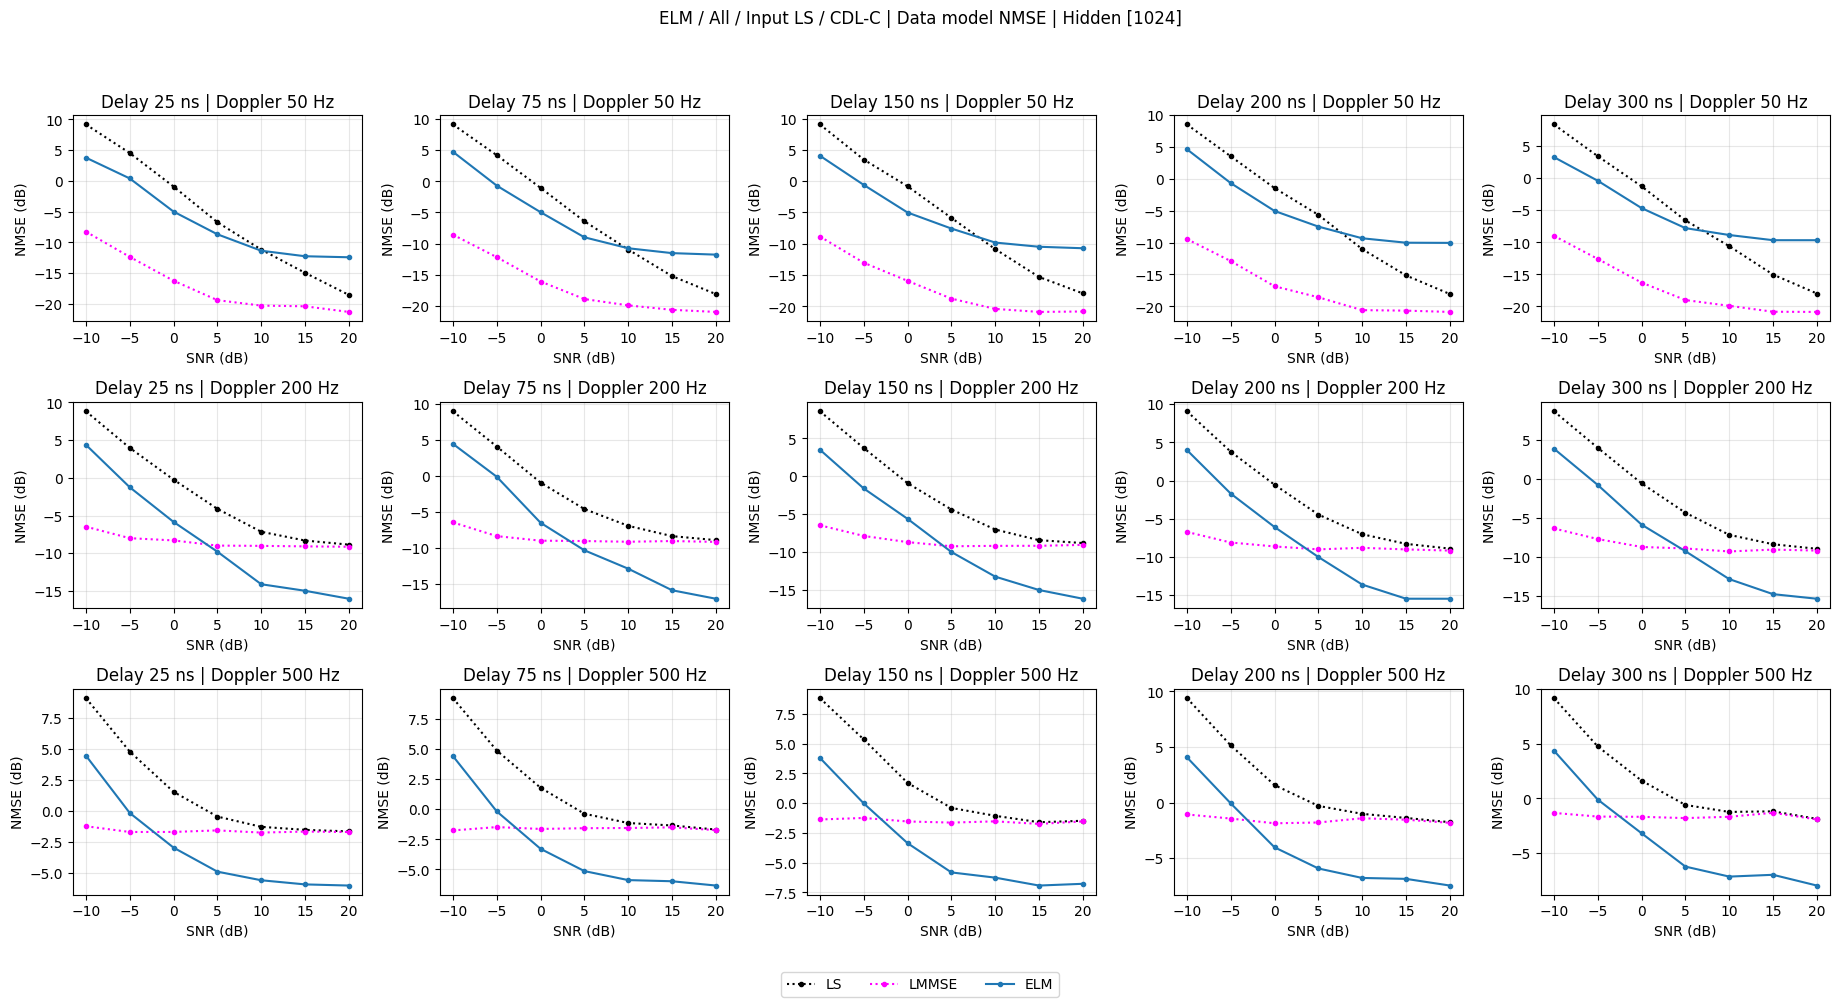

Doppler / Delay,25 ns,75 ns,150 ns,200 ns,300 ns
50 Hz,-10: x / 3.781-5: x / 0.3990: x / -4.9965: x / -8.68810: x / -11.35915: x / -12.25720: x / -12.424,-10: x / 4.741-5: x / -0.6970: x / -4.9645: x / -8.99810: x / -10.75915: x / -11.54120: x / -11.784,-10: x / 4.061-5: x / -0.5950: x / -5.0065: x / -7.56710: x / -9.80515: x / -10.47420: x / -10.711,-10: x / 4.649-5: x / -0.6670: x / -5.0355: x / -7.49010: x / -9.32015: x / -10.01520: x / -10.041,-10: x / 3.278-5: x / -0.4050: x / -4.6655: x / -7.78610: x / -8.86215: x / -9.67020: x / -9.673
200 Hz,-10: x / 4.373-5: x / -1.2540: x / -5.8515: x / -9.79810: x / -14.11415: x / -14.98020: x / -16.036,-10: x / 4.444-5: x / -0.1240: x / -6.5135: x / -10.33610: x / -12.89015: x / -15.88220: x / -17.060,-10: x / 3.487-5: x / -1.6230: x / -5.6305: x / -10.00210: x / -13.25315: x / -15.01820: x / -16.169,-10: x / 3.994-5: x / -1.7070: x / -6.0825: x / -10.00610: x / -13.61415: x / -15.46320: x / -15.466,-10: x / 3.890-5: x / -0.7640: x / -5.8495: x / -9.25510: x / -12.83415: x / -14.76220: x / -15.350
500 Hz,-10: x / 4.467-5: x / -0.1740: x / -2.9825: x / -4.92410: x / -5.62115: x / -5.95720: x / -6.050,-10: x / 4.404-5: x / -0.1830: x / -3.2885: x / -5.13410: x / -5.88115: x / -5.97720: x / -6.333,-10: x / 3.812-5: x / -0.0160: x / -3.3595: x / -5.81810: x / -6.25815: x / -6.92220: x / -6.775,-10: x / 4.071-5: x / -0.0720: x / -4.0235: x / -5.92310: x / -6.77515: x / -6.85720: x / -7.457,-10: x / 4.374-5: x / -0.1050: x / -3.1865: x / -6.23410: x / -7.15015: x / -6.98620: x / -7.969


Random Test: 105 환경 / 20000 samples / \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random Test LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random Test LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
ARSeparate | nslot: 1 | Mix Train/Val/Test: [100000, 30000, 0] | \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
ARSeparate | input [60, 1, 2] | CE bypass | Data input LS [60, 1, 2] | output [119, 8, 2]


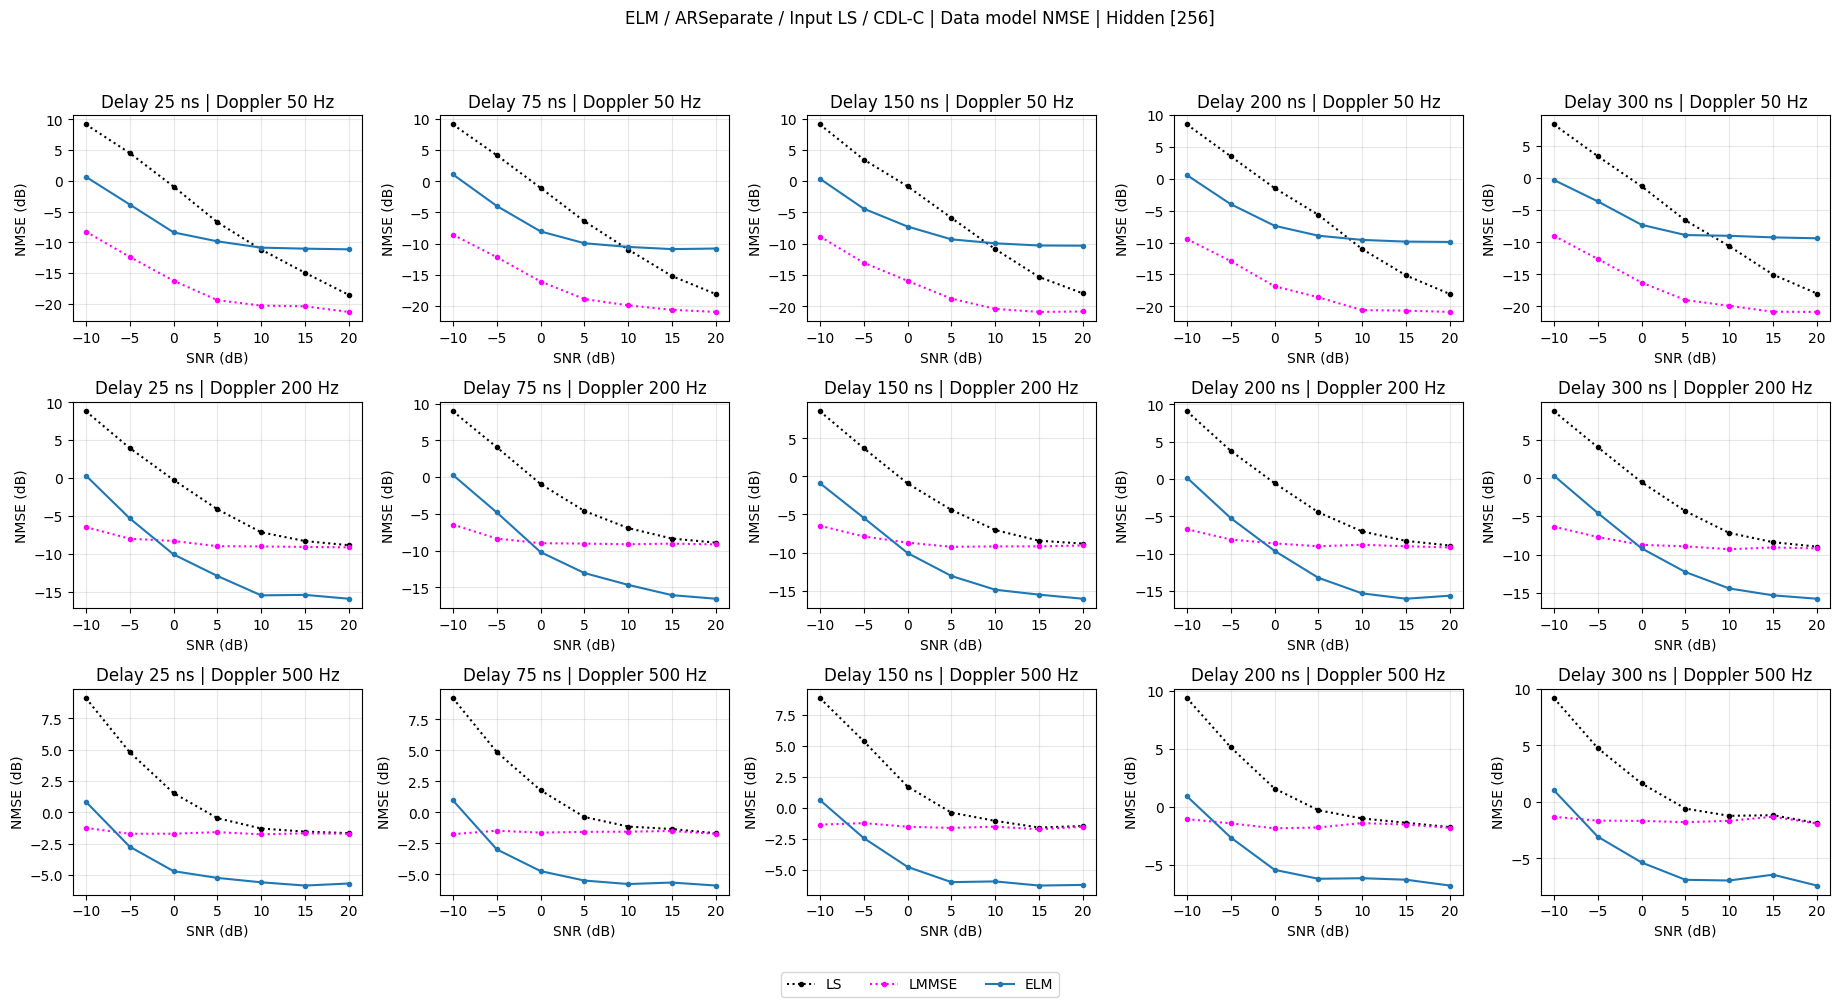

Doppler / Delay,25 ns,75 ns,150 ns,200 ns,300 ns
50 Hz,-10: x / 0.660-5: x / -3.8420: x / -8.3765: x / -9.83310: x / -10.85415: x / -11.02320: x / -11.131,-10: x / 1.104-5: x / -3.9620: x / -8.0555: x / -9.95210: x / -10.54415: x / -10.89820: x / -10.802,-10: x / 0.388-5: x / -4.3950: x / -7.2455: x / -9.29210: x / -9.92215: x / -10.27220: x / -10.305,-10: x / 0.592-5: x / -3.9710: x / -7.3565: x / -8.91610: x / -9.57515: x / -9.84320: x / -9.894,-10: x / -0.285-5: x / -3.6210: x / -7.2725: x / -8.86610: x / -8.98615: x / -9.23320: x / -9.372
200 Hz,-10: x / 0.328-5: x / -5.3180: x / -10.0835: x / -12.92410: x / -15.48715: x / -15.42220: x / -15.931,-10: x / 0.293-5: x / -4.8050: x / -10.2125: x / -13.06010: x / -14.67515: x / -16.07420: x / -16.561,-10: x / -0.892-5: x / -5.4410: x / -10.0665: x / -13.07710: x / -14.88215: x / -15.53020: x / -16.068,-10: x / 0.182-5: x / -5.2360: x / -9.6225: x / -13.22710: x / -15.31415: x / -16.03120: x / -15.623,-10: x / 0.290-5: x / -4.5610: x / -9.1635: x / -12.25310: x / -14.39015: x / -15.28720: x / -15.731
500 Hz,-10: x / 0.839-5: x / -2.7490: x / -4.7045: x / -5.24210: x / -5.59415: x / -5.85220: x / -5.690,-10: x / 0.961-5: x / -2.9880: x / -4.7425: x / -5.50310: x / -5.78515: x / -5.66620: x / -5.907,-10: x / 0.617-5: x / -2.4450: x / -4.7715: x / -5.99910: x / -5.94015: x / -6.27420: x / -6.224,-10: x / 0.909-5: x / -2.6560: x / -5.4485: x / -6.22310: x / -6.17415: x / -6.30420: x / -6.808,-10: x / 1.026-5: x / -3.0800: x / -5.3625: x / -6.89310: x / -6.95515: x / -6.44220: x / -7.402


Random Test: 105 환경 / 20000 samples / \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random Test LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random Test LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
ARShared | nslot: 1 | Mix Train/Val/Test: [100000, 30000, 0] | \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
ARShared | input [60, 1, 2] | CE bypass | Data input LS [60, 1, 2] | output [119, 8, 2]


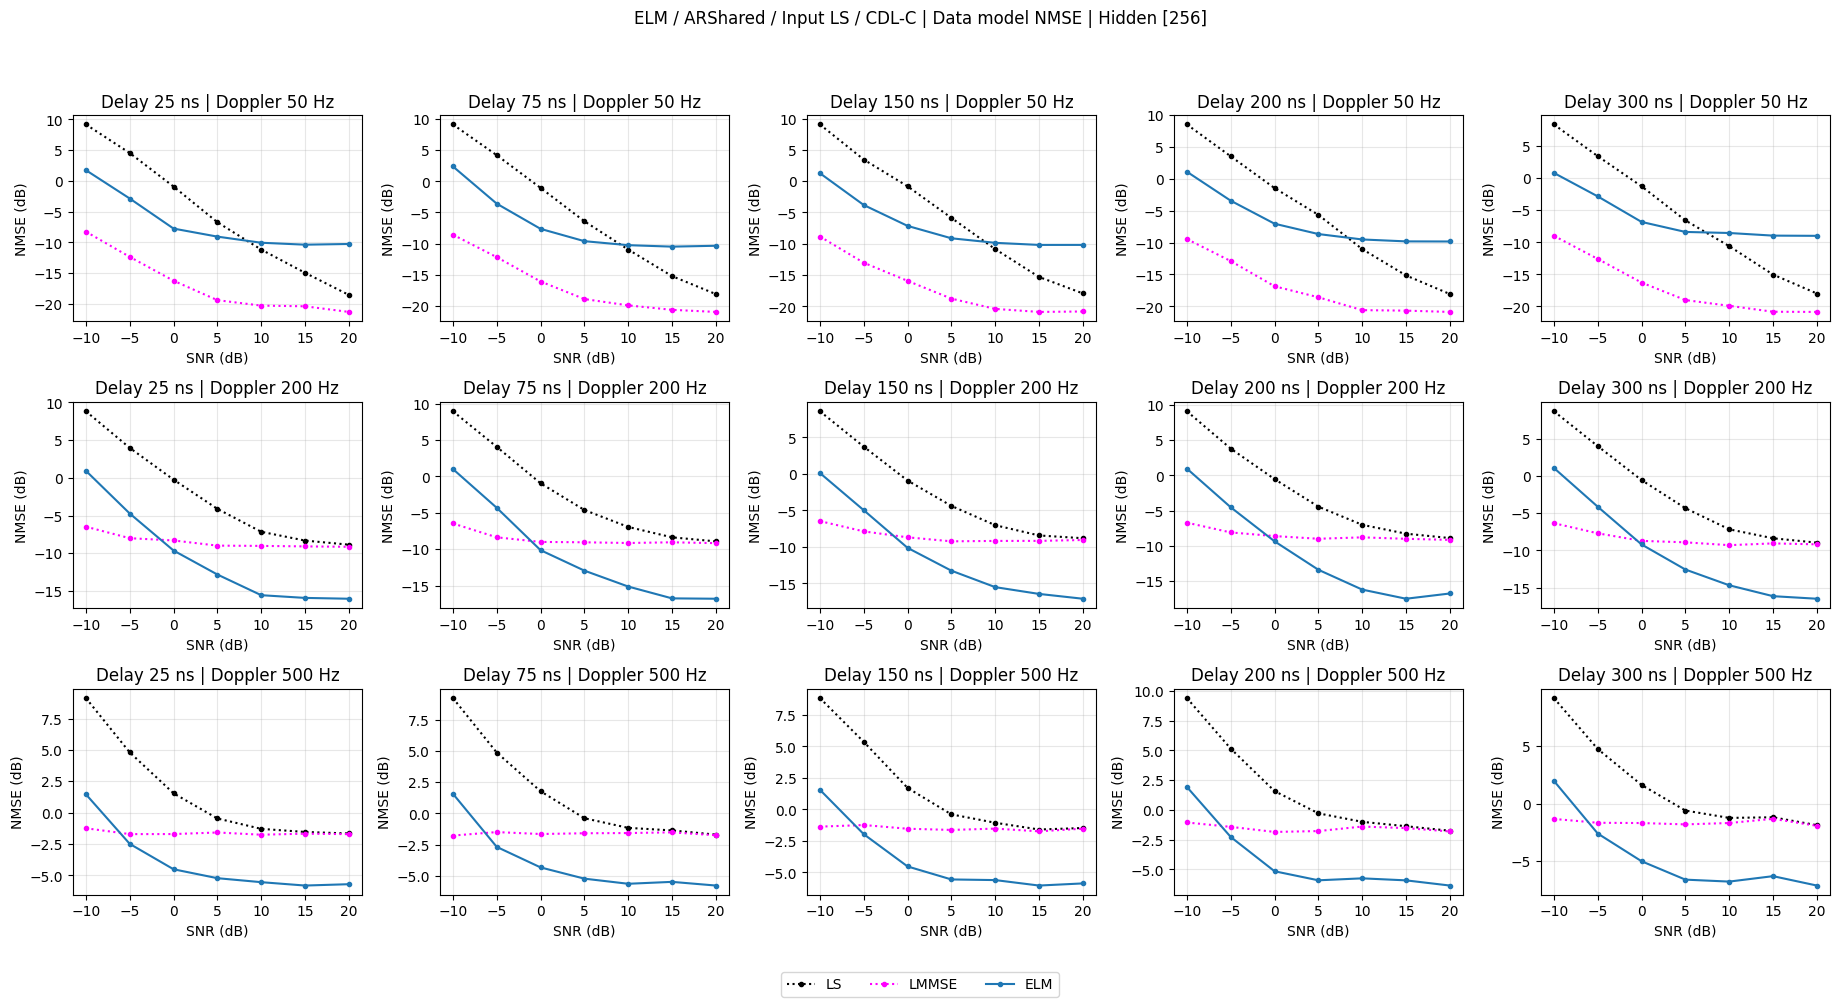

Doppler / Delay,25 ns,75 ns,150 ns,200 ns,300 ns
50 Hz,-10: x / 1.743-5: x / -2.8670: x / -7.7585: x / -9.06410: x / -10.06115: x / -10.37520: x / -10.263,-10: x / 2.386-5: x / -3.5940: x / -7.6425: x / -9.62110: x / -10.26415: x / -10.49920: x / -10.359,-10: x / 1.273-5: x / -3.8060: x / -7.1435: x / -9.12210: x / -9.84515: x / -10.18120: x / -10.178,-10: x / 1.119-5: x / -3.4270: x / -7.0355: x / -8.65610: x / -9.50615: x / -9.80720: x / -9.823,-10: x / 0.815-5: x / -2.8430: x / -6.8225: x / -8.38310: x / -8.54815: x / -8.95720: x / -8.990
200 Hz,-10: x / 0.926-5: x / -4.7350: x / -9.6415: x / -12.82110: x / -15.56115: x / -15.92120: x / -16.030,-10: x / 1.023-5: x / -4.3070: x / -10.1345: x / -12.94810: x / -15.13715: x / -16.76320: x / -16.813,-10: x / 0.104-5: x / -4.9880: x / -10.1425: x / -13.26910: x / -15.52015: x / -16.44920: x / -17.108,-10: x / 0.938-5: x / -4.5420: x / -9.3675: x / -13.40010: x / -16.21015: x / -17.50520: x / -16.762,-10: x / 1.072-5: x / -4.1290: x / -9.1935: x / -12.55810: x / -14.67115: x / -16.13420: x / -16.478
500 Hz,-10: x / 1.458-5: x / -2.4930: x / -4.5165: x / -5.22610: x / -5.54415: x / -5.81320: x / -5.706,-10: x / 1.573-5: x / -2.6680: x / -4.3055: x / -5.20210: x / -5.61115: x / -5.45820: x / -5.752,-10: x / 1.559-5: x / -1.9660: x / -4.5285: x / -5.56110: x / -5.61115: x / -6.04520: x / -5.876,-10: x / 1.917-5: x / -2.2860: x / -5.1695: x / -5.92910: x / -5.76515: x / -5.93420: x / -6.370,-10: x / 1.982-5: x / -2.5940: x / -5.0025: x / -6.60010: x / -6.77015: x / -6.29820: x / -7.114


Random Test: 105 환경 / 20000 samples / \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random Test LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random Test LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
ARAnchorSeparate | nslot: 1 | Mix Train/Val/Test: [100000, 30000, 0] | \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
ARAnchorSeparate | input [60, 1, 2] | CE bypass | Data input LS [60, 1, 2] | output [119, 8, 2]


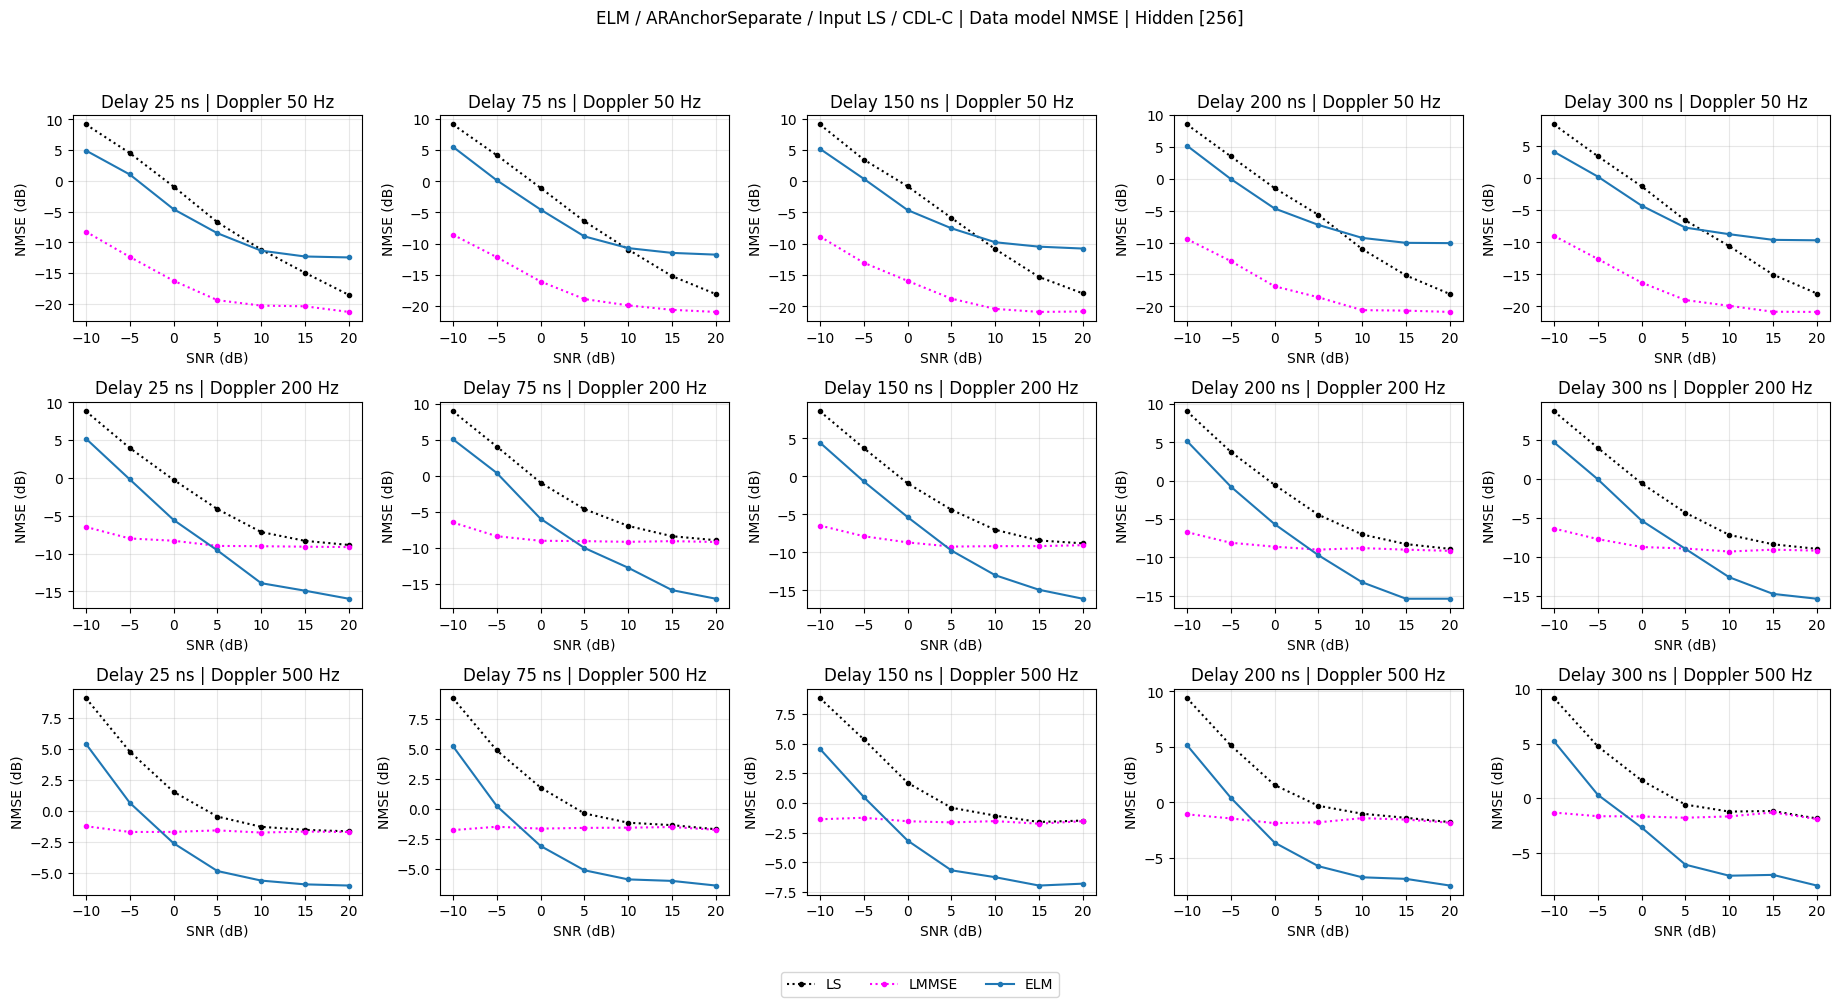

Doppler / Delay,25 ns,75 ns,150 ns,200 ns,300 ns
50 Hz,-10: x / 4.941-5: x / 1.0460: x / -4.6015: x / -8.51010: x / -11.35115: x / -12.29720: x / -12.451,-10: x / 5.545-5: x / 0.1640: x / -4.5415: x / -8.85210: x / -10.73515: x / -11.50520: x / -11.785,-10: x / 5.173-5: x / 0.3850: x / -4.6155: x / -7.52410: x / -9.75615: x / -10.45920: x / -10.761,-10: x / 5.210-5: x / -0.0130: x / -4.6435: x / -7.22210: x / -9.26015: x / -10.03520: x / -10.081,-10: x / 4.117-5: x / 0.2480: x / -4.2825: x / -7.71010: x / -8.73615: x / -9.61620: x / -9.688
200 Hz,-10: x / 5.203-5: x / -0.1860: x / -5.5505: x / -9.58210: x / -13.91915: x / -14.91320: x / -15.977,-10: x / 5.086-5: x / 0.4130: x / -5.9435: x / -9.99610: x / -12.74415: x / -15.84720: x / -17.043,-10: x / 4.433-5: x / -0.6760: x / -5.3655: x / -9.77010: x / -13.01715: x / -14.93420: x / -16.113,-10: x / 5.187-5: x / -0.7670: x / -5.6705: x / -9.73210: x / -13.27315: x / -15.42120: x / -15.418,-10: x / 4.709-5: x / -0.0270: x / -5.3225: x / -8.94810: x / -12.58515: x / -14.71920: x / -15.340
500 Hz,-10: x / 5.422-5: x / 0.6500: x / -2.6265: x / -4.87610: x / -5.65115: x / -5.95620: x / -6.052,-10: x / 5.216-5: x / 0.2380: x / -3.0815: x / -5.10210: x / -5.86115: x / -5.98520: x / -6.371,-10: x / 4.568-5: x / 0.5130: x / -3.1595: x / -5.66710: x / -6.24715: x / -6.95020: x / -6.791,-10: x / 5.169-5: x / 0.4280: x / -3.6105: x / -5.73310: x / -6.73315: x / -6.87520: x / -7.475,-10: x / 5.223-5: x / 0.3120: x / -2.6955: x / -6.10510: x / -7.11915: x / -7.04220: x / -8.021


Random Test: 105 환경 / 20000 samples / \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random Test LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random Test LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
ARAnchorShared | nslot: 1 | Mix Train/Val/Test: [100000, 30000, 0] | \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
ARAnchorShared | input [60, 1, 2] | CE bypass | Data input LS [60, 1, 2] | output [119, 8, 2]


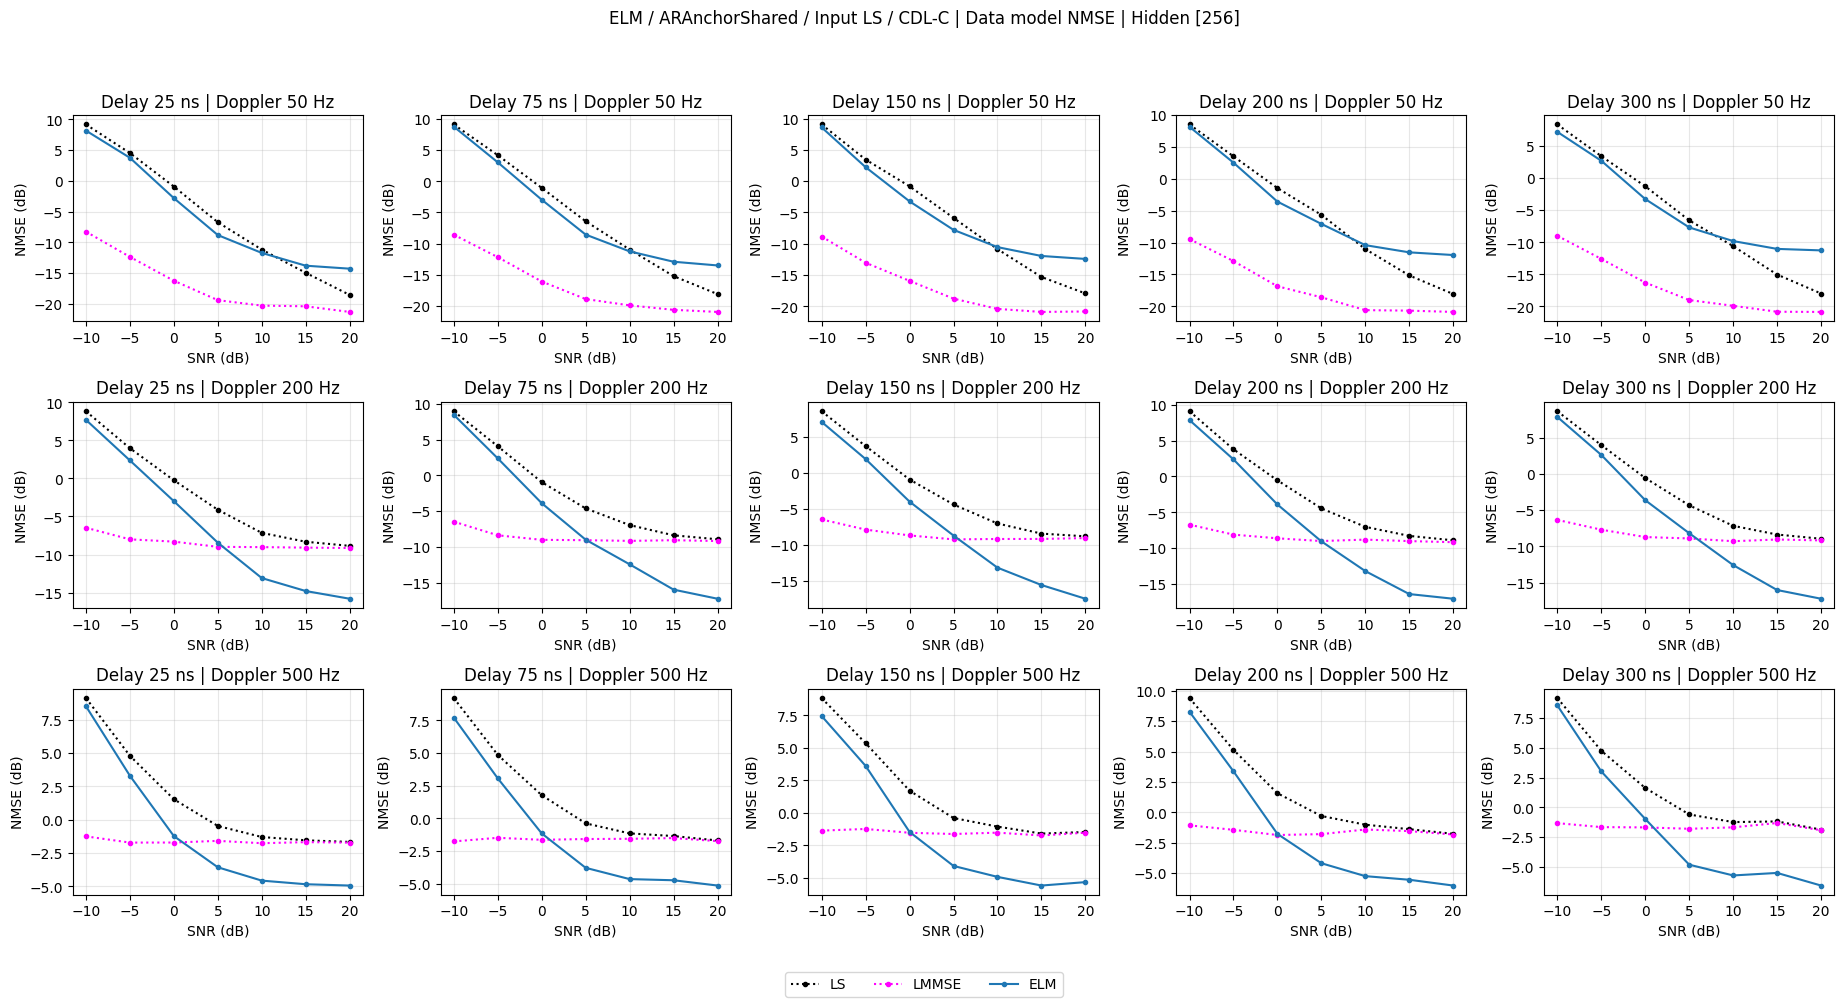

Doppler / Delay,25 ns,75 ns,150 ns,200 ns,300 ns
50 Hz,-10: x / 8.181-5: x / 3.7580: x / -2.8045: x / -8.81310: x / -11.71515: x / -13.79420: x / -14.279,-10: x / 8.782-5: x / 3.0450: x / -2.9615: x / -8.56610: x / -11.25915: x / -12.92620: x / -13.520,-10: x / 8.589-5: x / 2.2370: x / -3.2265: x / -7.77810: x / -10.53215: x / -11.94420: x / -12.417,-10: x / 8.168-5: x / 2.5420: x / -3.5665: x / -7.06810: x / -10.39815: x / -11.52720: x / -11.948,-10: x / 7.212-5: x / 2.7070: x / -3.2605: x / -7.68110: x / -9.80615: x / -11.02720: x / -11.258
200 Hz,-10: x / 7.689-5: x / 2.3610: x / -2.9915: x / -8.44310: x / -13.09315: x / -14.79620: x / -15.808,-10: x / 8.469-5: x / 2.3860: x / -3.8795: x / -8.98010: x / -12.42115: x / -15.96020: x / -17.233,-10: x / 7.076-5: x / 1.9140: x / -4.0005: x / -8.71610: x / -13.17915: x / -15.59120: x / -17.498,-10: x / 7.839-5: x / 2.3680: x / -3.9125: x / -9.04610: x / -13.18815: x / -16.38820: x / -17.038,-10: x / 7.892-5: x / 2.6410: x / -3.6175: x / -8.18310: x / -12.58815: x / -16.03920: x / -17.243
500 Hz,-10: x / 8.514-5: x / 3.2990: x / -1.2275: x / -3.56610: x / -4.56715: x / -4.83820: x / -4.937,-10: x / 7.713-5: x / 3.0670: x / -1.1505: x / -3.78310: x / -4.64615: x / -4.73520: x / -5.140,-10: x / 7.459-5: x / 3.6170: x / -1.4695: x / -4.08810: x / -4.93015: x / -5.59820: x / -5.336,-10: x / 8.271-5: x / 3.3760: x / -1.7715: x / -4.18110: x / -5.24215: x / -5.53920: x / -6.015,-10: x / 8.559-5: x / 3.0180: x / -0.9765: x / -4.81410: x / -5.71815: x / -5.50620: x / -6.566


Random Test: 105 환경 / 20000 samples / \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random Test LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random Test LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
Joint | nslot: 1 | Mix Train/Val/Test: [100000, 30000, 0] | \\?\E:\DMRS Channel\SISO\Mix\CDL-C\Random LS Channel\DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11\Random LS Channel 2D (DMRS SC60xSym2 P1 nslot1 Comb2 RB0-9 l2,11).h5
Joint | input [60, 1, 2] | CE bypass | Data input LS [60, 1, 2] | output [119, 8, 2]


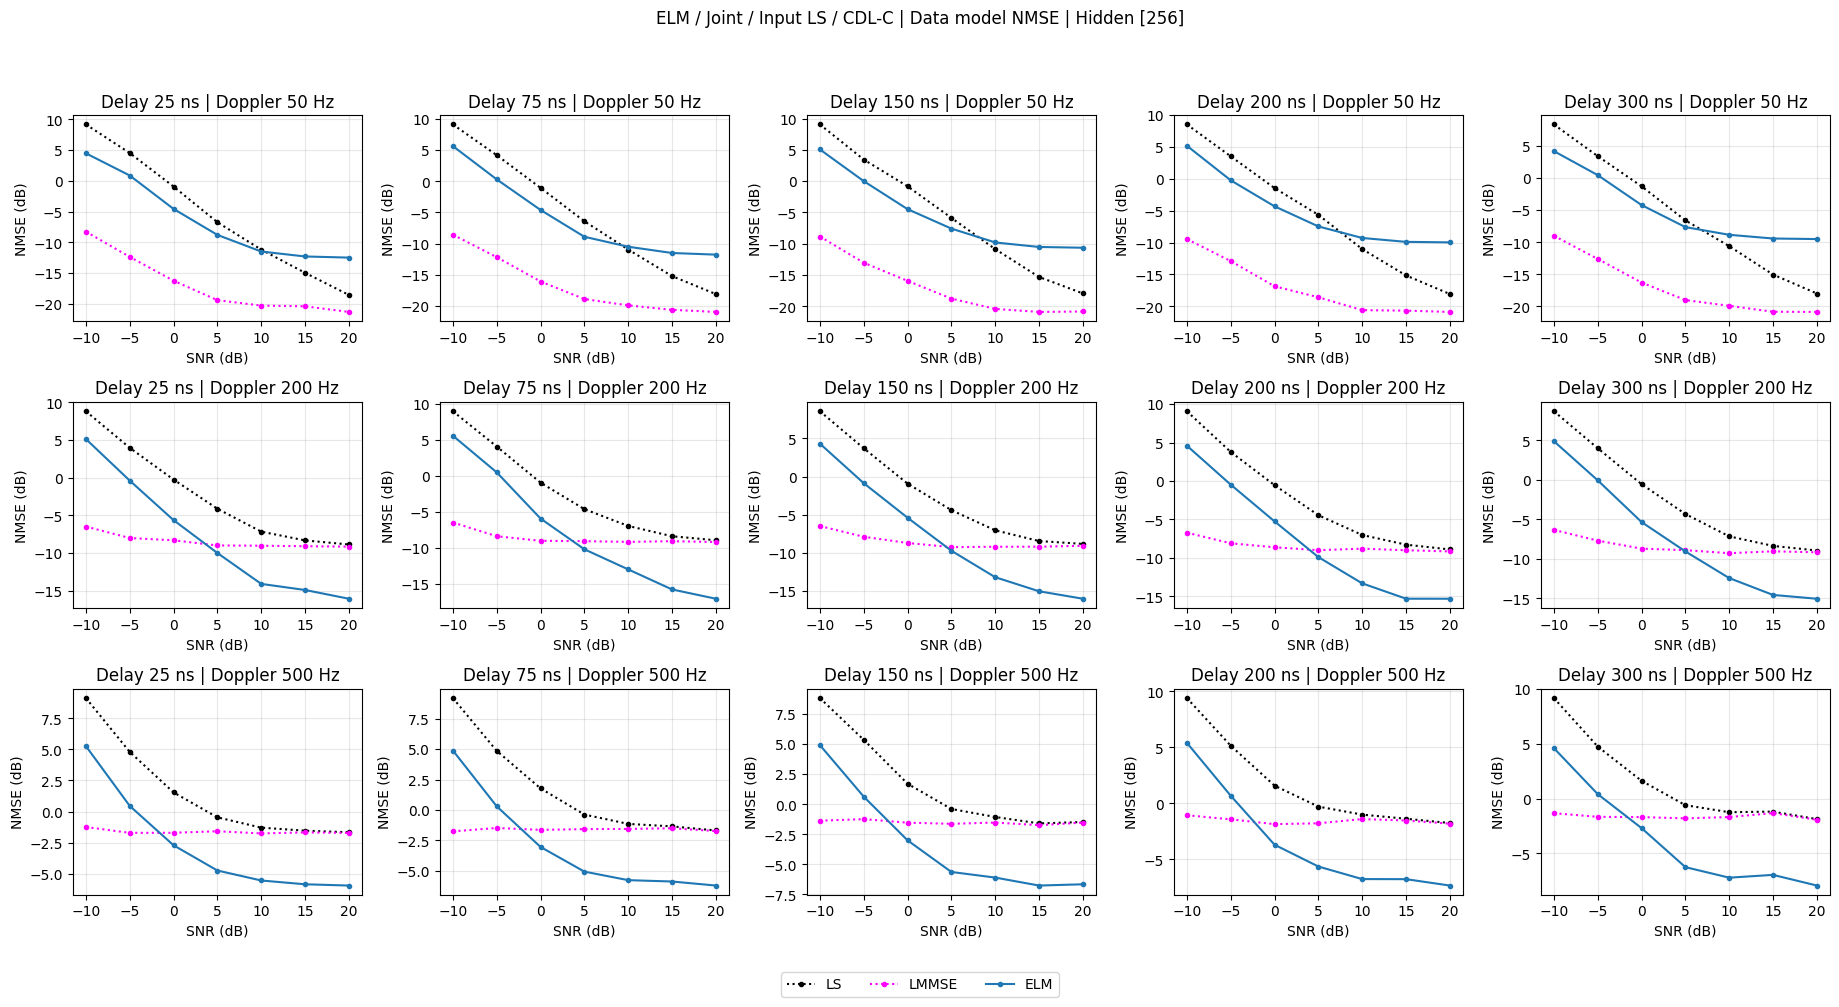

Doppler / Delay,25 ns,75 ns,150 ns,200 ns,300 ns
50 Hz,-10: x / 4.488-5: x / 0.8770: x / -4.5595: x / -8.78610: x / -11.48715: x / -12.29320: x / -12.479,-10: x / 5.652-5: x / 0.3070: x / -4.6075: x / -8.91410: x / -10.51415: x / -11.52020: x / -11.784,-10: x / 5.067-5: x / 0.0050: x / -4.4685: x / -7.57410: x / -9.78615: x / -10.50820: x / -10.630,-10: x / 5.191-5: x / -0.2300: x / -4.3095: x / -7.46210: x / -9.27115: x / -9.88320: x / -9.961,-10: x / 4.211-5: x / 0.4710: x / -4.1955: x / -7.63110: x / -8.82915: x / -9.40820: x / -9.493
200 Hz,-10: x / 5.131-5: x / -0.3840: x / -5.6315: x / -9.99110: x / -14.09215: x / -14.90020: x / -16.062,-10: x / 5.573-5: x / 0.4900: x / -5.9175: x / -10.17610: x / -12.96715: x / -15.74720: x / -17.036,-10: x / 4.312-5: x / -0.8660: x / -5.3915: x / -9.71910: x / -13.18515: x / -15.02820: x / -16.007,-10: x / 4.590-5: x / -0.4770: x / -5.2555: x / -9.90310: x / -13.31915: x / -15.31320: x / -15.318,-10: x / 4.889-5: x / -0.0650: x / -5.3465: x / -9.06510: x / -12.44015: x / -14.57420: x / -15.055
500 Hz,-10: x / 5.262-5: x / 0.4510: x / -2.7165: x / -4.74510: x / -5.54715: x / -5.85220: x / -5.954,-10: x / 4.894-5: x / 0.2950: x / -3.0485: x / -5.07810: x / -5.78015: x / -5.89220: x / -6.224,-10: x / 4.923-5: x / 0.6320: x / -3.0045: x / -5.63910: x / -6.10615: x / -6.76920: x / -6.665,-10: x / 5.395-5: x / 0.6720: x / -3.7045: x / -5.64810: x / -6.77015: x / -6.77720: x / -7.346,-10: x / 4.608-5: x / 0.4140: x / -2.6885: x / -6.24810: x / -7.20915: x / -6.95520: x / -7.928


In [9]:
OUTPUTS=[]
for requested_layout in LAYOUT_LIST:
    spec=model_spec(requested_layout);layout=spec['name'];GRID_NAME=grid_name(spec)
    activate_layout_sources(requested_layout)
    configuration,architecture=model_identity(spec)
    ce_config=config_for(CE_CONFIG,layout) if spec['source']=='CE' else None;data_config=config_for(DATA_CONFIG,layout)
    print(layout,'| input',spec['input_shape'],'| CE',spec['ce_output_shape'] if spec['source']=='CE' else 'bypass',
          '| Data input',spec['source'],spec['data_input_shape'],'| output',spec['data_output_shape'])
    environment_results={}
    for source in TRAIN_SOURCES:
        mode='MIX' if MIXED else 'FIX';channel=MIX_CHANNEL_TYPE if MIXED else CHANNEL_TYPE
        source_id=mix_id if MIXED else source['generation_id']
        environment=(None if MIXED else f"{channel}_Delay{source['condition']['delay_spread_ns']:g}ns_Doppler{source['condition']['doppler_hz']:g}Hz")
        case=(architecture+'_Mix'+source_id[:12] if MIXED else f"SNR{source['condition']['snr_db']:g}dB_"+architecture)
        root=filesystem_path(RESULT_ROOT/('Mix' if MIXED else 'Fix')/channel/GRID_NAME/MODEL_NAME/layout)
        if not MIXED:root=root/environment
        weight=root/'Model'/case/'Model.pth';ce_file=root/'Channel'/case/'CE_Train.h5';teacher_file=root/'Channel'/case/'Data_Train.h5'
        checkpoint=torch.load(weight,map_location='cpu',weights_only=True) if weight.is_file() else None
        if checkpoint and (checkpoint['configuration']!=configuration or checkpoint['source_id']!=source_id):raise ValueError('Saved model configuration/source mismatch.')
        teacher=None
        if MODEL_NAME=='ELM_Distill' and (checkpoint is None or not checkpoint.get('data_ready')):
            teacher=student_teacher(spec,source_id)
        middles=checkpoint.get('middle_sizes') if checkpoint else teacher['middle_sizes'] if teacher else None
        model=ChannelModel(spec,ce_config,data_config,middles).to(DEVICE)
        if checkpoint is None:
            checkpoint=compatible_legacy(model,configuration,source_id)
            if checkpoint:print('Compatible saved weights reused:',checkpoint['legacy_weight_source'])
        if checkpoint:model.load_state_dict(checkpoint['state_dict'],strict=True)
        if checkpoint is None:
            checkpoint=dict(format='dmrs-model-parts-1.0',family=MODEL_NAME,configuration=configuration,
                source_id=source_id,spec=spec,ce_ready=spec['source']!='CE',data_ready=False,middle_sizes=middles)
        need_train=(not checkpoint['data_ready'] or (spec['source']=='CE' and not ce_file.is_file()) or Distillation)
        if need_train:
            if MIXED:
                files={'dmrs/'+k:str(v) for k,v in mix_paths.items()};bounds=np.cumsum([0]+mix_metadata['counts'])
                rows=np.arange(bounds[2]);parts=dict(train=np.arange(bounds[1]),val=np.arange(bounds[1],bounds[2]),test=np.empty(0,dtype=np.int64))
            else:
                rows,original_parts=select_source_rows(source['split_ranges'],MAX_SAMPLES_PER_CONDITION)
                active=np.concatenate((original_parts['train'],original_parts['val']));rows=rows[active]
                parts=dict(train=np.arange(len(original_parts['train'])),val=np.arange(len(original_parts['train']),len(rows)),test=np.empty(0,dtype=np.int64));files=source['files']
            raw,real_rs,real_data=read_parts(files,rows,spec,source_id)
            prepare_environment_losses(files,rows,parts,source,weight.parent/'Environment_Loss',source_id)
            stats=checkpoint.get('scaler') or compute_train_stats(raw[parts['train']])
            if teacher:
                stats=teacher['metadata']['scaler'];teacher['rows']=rows
            x=normalize_data(raw,stats);rt=normalize_data(real_rs,stats);y=normalize_data(real_data,stats)
            del raw,real_rs,real_data
            cache=DATA_CACHE_DEVICE
            if cache=='auto':
                needed=4*(x.numel()+rt.numel()+y.numel())
                cache=str(DEVICE) if DEVICE.type=='cuda' and needed<torch.cuda.mem_get_info(DEVICE)[0]-2**30 else 'cpu'
            x,rt,y=x.to(cache),rt.to(cache),y.to(cache)
            logs={};start=time.perf_counter()
            if model.ce is not None:
                if not checkpoint['ce_ready']:
                    if teacher:
                        ce_state={k[3:]:v for k,v in teacher['checkpoint']['state_dict'].items() if k.startswith('ce.')}
                        model.ce.load_state_dict(ce_state,strict=True);logs['CE']=dict(algorithm='frozen matching Teacher CE')
                    else:
                        seed_everything(SEED)  # CE의 학습 난수는 뒤에 초기화한 Data 크기에 의존하지 않음.
                        logs['CE']=fit_map(model.ce,x,rt,parts,'CE')
                    checkpoint['ce_ready']=True
                for parameter in model.ce.parameters():parameter.requires_grad_(False)
                train_ce_file(model,x,rows,parts,stats,ce_file,source_id)
                corrected=ce_features(model,x,parts,ce_file,rows,source_id)
            else:corrected=None
            # CE만 완료된 중간 상태도 Model.pth 하나에 저장해 재시작 시 CE를 재학습하지 않습니다.
            checkpoint.update(state_dict=cpu_state(model),scaler=stats)
            atomic_checkpoint(weight,checkpoint)
            if not checkpoint['data_ready']:
                if spec['joint']:
                    packed=torch.cat((rt.flatten(1),y.flatten(1)),1)
                    logs['Data_Joint']=fit_map(model.joint,x,packed,parts,'Joint CE+Data')
                else:
                    anchor=model.data_input(x,corrected);logs['Data']=fit_data(model.data,anchor,y,parts,teacher)
                checkpoint['data_ready']=True
            elapsed=time.perf_counter()-start
            checkpoint.update(state_dict=cpu_state(model),scaler=stats,training_seconds=checkpoint.get('training_seconds',0.)+(elapsed if logs else 0.))
            atomic_checkpoint(weight,checkpoint);write_json(weight.parent/'Losses.json',logs)
            if Distillation:export_teacher(model,x,rows,parts,stats,teacher_file,configuration,source_id)
            del x,rt,y,corrected
        else:stats=checkpoint['scaler'];print('Saved Model.pth loaded -> Test:',weight)
        for test_source,test_rows,metrics,costs in test_evaluations(model,(TEST_SOURCES if MIXED else [source]),spec,stats):
            condition=test_source['condition']
            env=f"{condition['backend'].upper()}-{condition['profile']}_Delay{condition['delay_spread_ns']:g}ns_Doppler{condition['doppler_hz']:g}Hz"
            name=f"SNR{condition['snr_db']:g}dB_"+case if MIXED else case
            folder=root/'NMSE'/env/name if MIXED else root/'NMSE'/name;folder.mkdir(parents=True,exist_ok=True)
            settings=dict(format='dmrs-model-parts-1.0',status='complete',family=MODEL_NAME,reconstruction_layout=layout,
                branch=layout,data_mode=mode,mix_name=channel if MIXED else None,mix_id=source_id if MIXED else None,
                test_data_mode='Random' if test_source.get('storage')=='random_test' else 'Individual',
                test_sample_pair=metrics['sample_pair'],
                source_generation_id=test_source['generation_id'],test_rows_sha256=hashlib.sha256(test_rows.astype('<i8').tobytes()).hexdigest(),
                configuration=configuration,common_config=COMMON_CONFIG,ce_config=ce_config,data_config=data_config,
                data_input=spec['source'],context=spec['context'],n_slots=spec['n_slots'],scaler=stats,
                weight_path=str(weight),ce_train_path=str(ce_file) if model.ce is not None else None,
                model_config=data_config,grid_name=GRID_NAME,history_spec=spec,complexity=costs,condition=condition)
            result=dict(family=MODEL_NAME,reconstruction_layout=layout,branch=layout,data_mode=mode,
                test_data_mode='Random' if test_source.get('storage')=='random_test' else 'Individual',
                condition=condition,channel=metrics,complexity=costs,model_config=data_config,
                common_config=COMMON_CONFIG,ce_config=ce_config,data_config=data_config,data_input=spec['source'],
                mix_id=source_id if MIXED else None,history_spec=spec,n_slots=spec['n_slots'],training_seconds=checkpoint.get('training_seconds',0.))
            write_json(folder/'Settings.json',settings);write_json(folder/'Results.json',result)
            write_json(folder/'Sources.json',[test_source]);write_json(folder/'Channel_NMSE.json',metrics)
            write_json(folder/'CE_Reuse_NMSE.json',metrics['ce_reuse']);np.savez(folder/'Split_Indices.npz',test=test_rows)
            model_rows=[dict(model=name,symbols=str(value['symbols']),output_shape=str(value['output_shape']),
                mse=value['mse'],complex_elements=value['complex_elements'],samples=value['samples'],
                nmse_db=value['nmse_db'],squared_error=value['squared_error'],truth_power=value['truth_power'])
                for name,value in metrics['models'].items()]
            with (folder/'Model_NMSE.csv').open('w',encoding='utf-8-sig',newline='') as stream:
                writer=csv.DictWriter(stream,fieldnames=list(model_rows[0]));writer.writeheader();writer.writerows(model_rows)
            OUTPUTS.append(dict(folder=str(folder),results=result))
            environment_results.setdefault(env,[]).append(result)
        values=[value for group in environment_results.values() for value in group]
        plot_parts(values,root/'Comparison'/case)
        del model
        if DEVICE.type=='cuda':torch.cuda.empty_cache()


In [10]:
THROUGHPUT = False
THROUGHPUT_MCS_LIST = [0, 4, 7, 13, 20]
THROUGHPUT_DEMODULATION_LIST = ['MaxLog', 'LogMAP']
THROUGHPUT_FRAMES = 256
THROUGHPUT_BATCH_SIZE = 32
THROUGHPUT_LDPC_ITERATIONS = 12
THROUGHPUT_SEED = 20261021

if THROUGHPUT:
    # 학습에는 필요 없는 복조 / LDPC 라이브러리는 이 분기에서만 불러옵니다.
    from neoradium import Modem, LdpcCodec
    from neoradium.utils import goldSequence
    from IPython.display import display

    NR_MCS_TABLE_1 = [(2, r) for r in (120, 157, 193, 251, 308, 379, 449, 526, 602, 679)] + [(4, r) for r in (340, 378, 434, 490, 553, 616, 658)] + [(6, r) for r in (438, 466, 517, 567, 616, 666, 719, 772, 822, 873, 910, 948)]

    def nr_transport_block_size(n_re, qm, rate):
        info = float(n_re) * int(qm) * float(rate)
        if info <= 3824:
            n = max(3, int(np.log2(info)) - 6)
            quant = max(24, (1 << n) * math.floor(info / (1 << n)))
            table = np.array([24, 32, 40, 48, 56, 64, 72, 80, 88, 96, 104, 112, 120, 128, 136, 144, 152, 160, 168, 176, 184, 192, 208, 224, 240, 256, 272, 288, 304, 320, 336, 352, 368, 384, 408, 432, 456, 480, 504, 528, 552, 576, 608, 640, 672, 704, 736, 768, 808, 848, 888, 928, 984, 1032, 1064, 1128, 1160, 1192, 1224, 1256, 1288, 1320, 1352, 1416, 1480, 1544, 1608, 1672, 1736, 1800, 1864, 1928, 2024, 2088, 2152, 2216, 2280, 2408, 2472, 2536, 2600, 2664, 2728, 2792, 2856, 2976, 3104, 3240, 3368, 3496, 3624, 3752, 3824])
            return int(table[table >= quant][0])
        n = int(np.log2(info - 24)) - 5
        quant = max(3840, (1 << n) * round((info - 24) / (1 << n)))
        count = math.ceil((quant + 24) / (3816 if rate <= 0.25 else 8424)) if rate <= 0.25 or quant > 8424 else 1
        return int(8 * count * math.ceil((quant + 24) / (8 * count)) - 24)

    def mcs_configuration(index):
        if isinstance(index, bool) or int(index) != index or (not 0 <= int(index) < len(NR_MCS_TABLE_1)):
            raise ValueError('THROUGHPUT_MCS_LIST에는 표 1의 정수 MCS index 0~28을 입력하세요.')
        (qm, rate1024) = NR_MCS_TABLE_1[int(index)]
        return dict(mcs_index=int(index), modulation={2: 'QPSK', 4: '16QAM', 6: '64QAM'}[qm], qm=qm, rate1024=rate1024, target_code_rate=rate1024 / 1024)

    def mmse_llrs(received, h_est, noise, tx_epre, modulation, device):
        """MMSE equalization + gain-aware max-log QAM demapping. Positive LLR -> 0."""
        modem = Modem(modulation)
        qm = modem.qm
        bits = (np.arange(2 ** qm)[:, None] >> np.arange(qm - 1, -1, -1) & 1).astype(np.int8)
        constellation = modem.modulate(bits.ravel()) * np.sqrt(tx_epre)
        y = torch.as_tensor(received, dtype=torch.complex64, device=device).transpose(1, 2).flatten(1)
        h = torch.as_tensor(h_est, dtype=torch.complex64, device=device).transpose(1, 2).flatten(1)
        n0 = max(float(noise), 1e-12)
        denominator = h.abs().square() + n0 / tx_epre
        w = h.conj() / denominator
        equalized = w * y
        gain = w * h
        variance = (w.abs().square() * n0).clamp_min(1e-20)
        constellation = torch.as_tensor(constellation, dtype=torch.complex64, device=device)
        distance = (equalized[:, :, None] - gain[:, :, None] * constellation).abs().square() / variance[:, :, None]
        llrs = []
        for bit in range(qm):
            llrs.append(distance[:, :, bits[:, bit] == 1].amin(-1) - distance[:, :, bits[:, bit] == 0].amin(-1))
        values = torch.stack(llrs, dim=-1).flatten(1).clamp(-50, 50)
        if not torch.isfinite(values).all():
            raise FloatingPointError('Nonfinite QAM LLRs.')
        return values.cpu().numpy()

    def soft_link_llrs(received, h_est, noise, tx_epre, modulation, device, demodulation):
        if demodulation == 'MaxLog':
            return mmse_llrs(received, h_est, noise, tx_epre, modulation, device)
        if demodulation != 'LogMAP':
            raise ValueError('복조 방식은 MaxLog 또는 LogMAP을 사용하세요.')
        modem = Modem(modulation)
        qm = modem.qm
        bits = (np.arange(2 ** qm)[:, None] >> np.arange(qm - 1, -1, -1) & 1).astype(np.int8)
        constellation = torch.as_tensor(modem.modulate(bits.ravel()) * np.sqrt(tx_epre), dtype=torch.complex64, device=device)
        y = torch.as_tensor(received, dtype=torch.complex64, device=device).transpose(1, 2).flatten(1)
        h = torch.as_tensor(h_est, dtype=torch.complex64, device=device).transpose(1, 2).flatten(1)
        n0 = max(float(noise), 1e-12)
        w = h.conj() / (h.abs().square() + n0 / tx_epre)
        (equalized, gain) = (w * y, w * h)
        variance = (w.abs().square() * n0).clamp_min(1e-20)
        distance = (equalized[:, :, None] - gain[:, :, None] * constellation).abs().square() / variance[:, :, None]
        llrs = [torch.logsumexp(-distance[:, :, bits[:, bit] == 0], dim=-1) - torch.logsumexp(-distance[:, :, bits[:, bit] == 1], dim=-1) for bit in range(qm)]
        values = torch.stack(llrs, dim=-1).flatten(1).clamp(-50, 50)
        if not torch.isfinite(values).all():
            raise FloatingPointError('Nonfinite LogMAP LLRs.')
        return values.cpu().numpy()

    # 저장 Channel 없이 Model.pth를 직접 실행합니다. 학습과 독립된 마지막 선택 분기입니다.
    link_cases=list(globals().get('OUTPUTS',[]))
    if not link_cases:
        for layout_value in LAYOUT_LIST:
            spec=model_spec(layout_value);config,_=model_identity(spec)
            root=filesystem_path(RESULT_ROOT/('Mix' if MIXED else 'Fix')/(MIX_CHANNEL_TYPE if MIXED else CHANNEL_TYPE)/grid_name(spec)/MODEL_NAME/spec['name'])
            for path in root.rglob('Settings.json'):
                saved=json.loads(path.read_text(encoding='utf-8'))
                if saved.get('status')=='complete' and saved.get('configuration')==config:
                    link_cases.append(dict(folder=str(path.parent)))
    THROUGHPUT_OUTPUTS=[]
    for output in link_cases:
        folder=filesystem_path(output['folder']);saved_settings=json.loads((folder/'Settings.json').read_text(encoding='utf-8'))
        source=json.loads((folder/'Sources.json').read_text(encoding='utf-8'))[0]
        model_path=filesystem_path(saved_settings['weight_path']);checkpoint=torch.load(model_path,map_location='cpu',weights_only=True)
        if not checkpoint.get('data_ready'):raise ValueError('Data 학습이 완료되지 않은 가중치입니다.')
        if checkpoint['configuration']!=saved_settings['configuration']:raise ValueError('가중치 설정과 NMSE 설정이 다릅니다.')
        spec=checkpoint['spec'];config=checkpoint['configuration'];inference_layout=spec['name']
        model=ChannelModel(spec,config['ce'],config['data'],checkpoint.get('middle_sizes')).to(DEVICE).eval()
        model.load_state_dict(checkpoint['state_dict'],strict=True)
        with np.load(folder/'Split_Indices.npz',allow_pickle=False) as saved:rows=saved['test'][:THROUGHPUT_FRAMES]
        raw_ls,real_rs,real_data=read_parts(source['files'],rows,spec,source['generation_id'])
        stats=checkpoint['scaler'];predictions=[]
        with torch.inference_mode():
            for lo in range(0,len(rows),THROUGHPUT_BATCH_SIZE):
                _,data=model(normalize_data(raw_ls[lo:lo+THROUGHPUT_BATCH_SIZE],stats).to(DEVICE))
                predictions.append(denormalize_data(data,tuple(spec['data_shape']),stats).cpu().numpy())
        with h5py.File(source['files']['dmrs/mmse'],'r') as file:
            if str(file.attrs['generation_id'])!=str(source['generation_id']):raise ValueError('Throughput MMSE source differs.')
            chosen,inv=np.unique(rows,return_inverse=True);k=file['Subcarrier_Indices'][...];sy=file['Symbol_Indices'][...]
            mmse=file['MMSE_Channel'][chosen,-1,0,0][inv][:,np.searchsorted(k,spec['rs_subcarriers'])][:,:,np.searchsorted(sy,spec['current_symbols'])]
        current=raw_ls[:,:,-len(spec['current_symbols']):]
        estimates={'LS':reference_grid(current,spec['current_symbols'],spec),
                   'LMMSE':reference_grid(mmse,spec['current_symbols'],spec),
                   'Model':np.concatenate(predictions),'Real':real_data}
        n_sc,n_symbols=spec['data_shape']
        condition = source['condition']
        if source['config']['carrier']['scs_khz'] != 15:
            raise ValueError('이 코드는 15 kHz / 1 ms 슬롯을 평가합니다.')
        tx_epre = float(source['config']['tx_epre'])
        noise_variance = tx_epre * 10 ** (-condition['snr_db'] / 10) if source['config']['noise_enabled'] else 0.0
        slot_duration = 0.001
        weight_sha = hashlib.sha256(model_path.read_bytes()).hexdigest()
        logical_model_folder = model_path.parent
        row_sha = hashlib.sha256(rows.astype('<i8').tobytes()).hexdigest()

        for mcs_index in THROUGHPUT_MCS_LIST:
            mcs = mcs_configuration(mcs_index)
            qm, rate = mcs['qm'], mcs['target_code_rate']
            coded_size = n_sc * n_symbols * qm
            payload_size = nr_transport_block_size(n_sc * n_symbols, qm, rate)
            crc_size = 16 if payload_size <= 3824 else 24
            crc_name = '16' if crc_size == 16 else '24A'
            # NeoRadium의 내부 TB 길이에서 CRC16 / CRC24A 길이를 맞춥니다.
            block = LdpcCodec(mcs['modulation'], rate, payload_size + crc_size - 24,
                             numLayers=1, numIter=THROUGHPUT_LDPC_ITERATIONS).cwCodecs[0]
            if block.baseGraphNo != LdpcCodec.getBaseGraphNo(payload_size, rate):
                raise ValueError('NR TBS / LDPC base graph가 다릅니다.')
            noise_seed = int(hashlib.sha256((source['generation_id'] + str(THROUGHPUT_SEED) + str(mcs_index)).encode()).hexdigest()[:8], 16)
            payload_rng = np.random.default_rng(THROUGHPUT_SEED + int(mcs_index))
            noise_rng = np.random.default_rng(noise_seed)
            payload = payload_rng.integers(0, 2, size=(len(rows), payload_size), dtype=np.int8)
            coded = np.stack([block.rateMatch(block.encodeCodeBlocks(block.doSegmentation(block.appendCrc(bits, crc_name))), coded_size) for bits in payload])
            scramble = np.asarray(goldSequence((1 << 15) + 1, coded_size), dtype=np.int8)
            modem = Modem(mcs['modulation'])
            transmitted = modem.modulate((coded ^ scramble[None]).ravel()).reshape(len(rows), n_symbols, n_sc).transpose(0, 2, 1)
            transmitted = transmitted * np.sqrt(tx_epre)
            noise = np.sqrt(noise_variance / 2) * (noise_rng.standard_normal(real_data.shape) + 1j * noise_rng.standard_normal(real_data.shape))
            # SISO OFDM 데이터 RE: 실제 Test 채널 H에 같은 송신 데이터와 AWGN을 적용합니다.
            received = (real_data * transmitted + noise).astype(np.complex64)

            for demodulation in THROUGHPUT_DEMODULATION_LIST:
                if demodulation not in ('MaxLog', 'LogMAP'):
                    raise ValueError('복조 방식은 MaxLog / LogMAP 중 선택하세요.')
                measurements = {}
                for method, estimate in estimates.items():
                    passed_crc = verified = coded_errors = payload_errors = undetected = 0
                    loop = tqdm(range(0, len(rows), THROUGHPUT_BATCH_SIZE),
                                desc=f'{MODEL_NAME} | MCS {mcs_index} | {demodulation} | {method}',unit='batch')
                    for start in loop:
                        stop = min(start + THROUGHPUT_BATCH_SIZE, len(rows))
                        llrs = soft_link_llrs(received[start:stop], estimate[start:stop], noise_variance,
                            tx_epre, mcs['modulation'], 'cpu', demodulation)
                        llrs *= 1 - 2 * scramble[None]
                        coded_errors += int(np.count_nonzero((llrs < 0) != coded[start:stop]))
                        for i, llr in enumerate(llrs, start):
                            decoded = block.decodeCodeBlocks(block.recoverRate(llr))
                            merged, cb_crc = block.checkCrcAndMerge(decoded)
                            merged = merged[:payload_size + crc_size]
                            crc_ok = bool(np.asarray(block.checkCrc(merged, crc_name)).all() and np.asarray(cb_crc).all())
                            errors = int(np.count_nonzero(merged[:payload_size] != payload[i]))
                            passed_crc += int(crc_ok)
                            verified += int(crc_ok and errors == 0)
                            undetected += int(crc_ok and errors > 0)
                            payload_errors += errors
                    measurements[method] = dict(frames=len(rows), payload_bits=payload_size, crc=crc_name,
                        verified_successes=verified, crc_successes=passed_crc, block_errors=len(rows) - verified,
                        bler=1 - verified / len(rows), throughput_mbps=verified * payload_size / (len(rows) * slot_duration) / 1e6,
                        maximum_throughput_mbps=payload_size / slot_duration / 1e6,
                        coded_ber=coded_errors / (len(rows) * coded_size), payload_ber=payload_errors / (len(rows) * payload_size),
                        undetected_crc_errors=undetected)
                record = dict(family=MODEL_NAME, model_size=f"CE {config['ce']}, Data {config['data']}", model_folder=str(logical_model_folder), condition=condition,
                    layout=inference_layout, data_mode=saved_settings['data_mode'],
                    mcs=mcs, demodulation=demodulation, ldpc_iterations=THROUGHPUT_LDPC_ITERATIONS,
                    source_generation_id=source['generation_id'], test_rows_sha256=row_sha,
                    weight_sha256=weight_sha, seed=THROUGHPUT_SEED, data_symbols=spec['data_symbols'],
                    link_model='SISO frequency-domain H*x+AWGN on original physical Test data REs',
                    throughput_definition='Correct CRC-passing payload bits / full 1 ms slot, no HARQ',
                    channels_saved=False, measurements=measurements)
                if inference_layout == 'All_Test':
                    record.update(inference_only=True,inference_policy=saved_settings['inference_policy'],
                        weight_source_path=str(model_path))
                write_json(folder / 'Throughput' / f'MCS{mcs_index}_{demodulation}.json', record)
                THROUGHPUT_OUTPUTS.append(record)
        del model, predictions, estimates, raw_ls, real_rs, real_data, received

    # 같은 모델 / 환경 / MCS / 복조 방식의 SNR 결과를 모읍니다.
    grouped = {}
    for record in THROUGHPUT_OUTPUTS:
        c = record['condition']
        key = (record['model_folder'], c['backend'], c['profile'], c['delay_spread_ns'], c['doppler_hz'],
               record['mcs']['mcs_index'], record['demodulation'])
        # FIX에서는 가중치 폴더의 SNR 접두사를 제외해야 같은 환경의 SNR이 모입니다.
        if record['data_mode'] == 'FIX':
            key = (str(Path(record['model_folder']).parent / Path(record['model_folder']).name.split('_', 1)[1]), *key[1:])
        grouped.setdefault(key, []).append(record)
    for key, records in grouped.items():
        records.sort(key=lambda value: value['condition']['snr_db'])
        if {float(value['condition']['snr_db']) for value in records} != set(map(float, TEST_SNR_LIST)):
            print('Throughput SNR 평가가 모두 완료된 후 그림을 출력합니다:', key)
            continue
        for metric, ylabel in [('throughput_mbps', 'Throughput (Mbps)'), ('bler', 'BLER')]:
            fig, ax = plt.subplots(figsize=(11, 6))
            for method in ('LS', 'LMMSE', 'Model', 'Real'):
                ax.plot([value['condition']['snr_db'] for value in records],
                        [value['measurements'][method][metric] for value in records], marker='o', label=method)
            c, mcs = records[0]['condition'], records[0]['mcs']
            ax.set(title=f"{MODEL_NAME} ({records[0]['model_size']}) / {records[0]['layout']} / {records[0]['data_mode']}\n"
                f"{c['backend'].upper()}-{c['profile']} Delay {c['delay_spread_ns']:g} ns, Doppler {c['doppler_hz']:g} Hz | MCS {mcs['mcs_index']} {mcs['modulation']} | {records[0]['demodulation']}",
                xlabel='SNR (dB)', ylabel=ylabel)
            ax.grid(alpha=0.3)
            fig.legend(*ax.get_legend_handles_labels(), loc='lower center', ncol=4)
            fig.subplots_adjust(bottom=0.2, top=0.8)
            environment = f"{c['backend'].upper()}-{c['profile']}_Delay{c['delay_spread_ns']:g}ns_Doppler{c['doppler_hz']:g}Hz"
            plot_folder = filesystem_path(Path(key[0]).parent / 'Throughput_Comparison' / Path(key[0]).name / environment)
            plot_folder.mkdir(parents=True, exist_ok=True)
            fig.savefig(plot_folder / f"MCS{mcs['mcs_index']}_{records[0]['demodulation']}_{metric}.png", dpi=150)
            plt.close(fig)
            display(fig)
